<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/58/Uber_logo_2018.svg/1024px-Uber_logo_2018.svg.png" alt="UBER LOGO" width="50%" />

# UBER Pickups 

## Company's Description 📇

<a href="http://uber.com/" target="_blank">Uber</a> is one of the most famous startup in the world. It started as a ride-sharing application for people who couldn't afford a taxi. Now, Uber expanded its activities to Food Delivery with <a href="https://www.ubereats.com/fr-en" target="_blank">Uber Eats</a>, package delivery, freight transportation and even urban transportation with <a href="https://www.uber.com/fr/en/ride/uber-bike/" target="_blank"> Jump Bike</a> and <a href="https://www.li.me/" target="_blank"> Lime </a> that the company funded. 


The company's goal is to revolutionize transportation accross the globe. It operates now on about 70 countries and 900 cities and generates over $14 billion revenue! 😮


## Project 🚧

One of the main pain point that Uber's team found is that sometimes drivers are not around when users need them. For example, a user might be in San Francisco's Financial District whereas Uber drivers are looking for customers in Castro.  

(If you are not familiar with the bay area, check out <a href="https://www.google.com/maps/place/San+Francisco,+CA,+USA/@37.7515389,-122.4567213,13.43z/data=!4m5!3m4!1s0x80859a6d00690021:0x4a501367f076adff!8m2!3d37.7749295!4d-122.4194155" target="_blank">Google Maps</a>)

Eventhough both neighborhood are not that far away, users would still have to wait 10 to 15 minutes before being picked-up, which is too long. Uber's research shows that users accept to wait 5-7 minutes, otherwise they would cancel their ride. 

Therefore, Uber's data team would like to work on a project where **their app would recommend hot-zones in major cities to be in at any given time of day.**  

## Goals 🎯

Uber already has data about pickups in major cities. Your objective is to create algorithms that will determine where are the hot-zones that drivers should be in. Therefore you will:

* Create an algorithm to find hot zones 
* Visualize results on a nice dashboard 

## Scope of this project 🖼️

To start off, Uber wants to try this feature in New York city. Therefore you will only focus on this city. Data can be found here: 

👉👉<a href="https://full-stack-bigdata-datasets.s3.eu-west-3.amazonaws.com/Machine+Learning+non+Supervis%C3%A9/Projects/uber-trip-data.zip" target="_blank"> Uber Trip Data</a> 👈👈

**You only need to focus on New York City for this project**

## Helpers 🦮

To help you achieve this project, here are a few tips that should help you: 

### Clustering is your friend 

Clustering technics are a perfect fit for the job. Think about it, all the pickup locations can be gathered into different clusters. You can then use **cluster coordinates to pin hot zones** 😉
    

### Create maps with `plotly` 

Check out <a href="https://plotly.com/" target="_blank">Plotly</a> documentation, you can create maps and populate them easily. Obviously, there are other libraries but this one should do the job pretty well. 


### Start small grow big 

Eventhough Uber wants to have hot-zones per hour and per day of week, you should first **start small**. Pick one day at a given hour and **then start to generalize** your approach. 

## Deliverable 📬

To complete this project, your team should: 

* Have a map with hot-zones using any python library (`plotly` or anything else). 
* You should **at least** describe hot-zones per day of week. 
* Compare results with **at least** two unsupervised algorithms like KMeans and DBScan. 

Your maps should look something like this: 

<img src="https://full-stack-assets.s3.eu-west-3.amazonaws.com/images/Clusters_uber_pickups.png" alt="Uber Cluster Map" />

# 1. load data

In [1]:
# load data 

import pandas as pd
from pathlib import Path
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
dir_data = "./uber-trip-data"
taxi_zone_name = "taxi-zone-lookup.csv"
NYC_boroughs = ['Queens', 'Bronx', 'Manhattan', 'Staten Island', 'Brooklyn']


In [2]:

dir_data = "./uber-trip-data"

In [3]:
prefix = "uber-raw-data"
files_list = [p.name for p in Path(dir_data).glob(f"{prefix}*.csv")]

In [4]:
files_list =  sorted(files_list)
files_list

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-janjune-15.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [5]:
files_list2 =  files_list.copy()
files_list2.pop(2)
files_list2

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [6]:
files_list3 =  files_list.copy()
files_list3.remove("uber-raw-data-janjune-15.csv")
files_list3

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [7]:
files_list

['uber-raw-data-apr14.csv',
 'uber-raw-data-aug14.csv',
 'uber-raw-data-janjune-15.csv',
 'uber-raw-data-jul14.csv',
 'uber-raw-data-jun14.csv',
 'uber-raw-data-may14.csv',
 'uber-raw-data-sep14.csv']

In [8]:
uber_raw = pd.DataFrame()
dtype_list = {'Date/Time': str,'Lat': float,'Lon': float,
                                                      'Base': str}
for f in files_list3:
    df_raw = pd.read_csv(f"{dir_data}/{f}", dtype=dtype_list)
    print(len(df_raw))
    uber_raw = pd.concat([uber_raw,df_raw])
print(len(uber_raw))

564516
829275
796121
663844
652435
1028136
4534327


In [9]:
print(uber_raw.head())

          Date/Time      Lat      Lon    Base
0  4/1/2014 0:11:00  40.7690 -73.9549  B02512
1  4/1/2014 0:17:00  40.7267 -74.0345  B02512
2  4/1/2014 0:21:00  40.7316 -73.9873  B02512
3  4/1/2014 0:28:00  40.7588 -73.9776  B02512
4  4/1/2014 0:33:00  40.7594 -73.9722  B02512


In [10]:
uber_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 1028135
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   Date/Time  object 
 1   Lat        float64
 2   Lon        float64
 3   Base       object 
dtypes: float64(2), object(2)
memory usage: 173.0+ MB


## 1.2 load one file 

In [11]:
# read special file 2015 with different columns from the other files
filename2 = 'uber-raw-data-janjune-15.csv'
df_uber2 = pd.read_csv(f"{dir_data}/{filename2}")
df_uber2.head()

,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID
0,B02617,2015-05-17 09:47:00,B02617,141
1,B02617,2015-05-17 09:47:00,B02617,65
2,B02617,2015-05-17 09:47:00,B02617,100
3,B02617,2015-05-17 09:47:00,B02774,80
4,B02617,2015-05-17 09:47:00,B02617,90


In [12]:
#will not be used immediately as no coordinates are identified, to be joined with taxi_zone :

In [13]:
# taxi_zone : 
taxi_zone_df = pd.read_csv(f"{dir_data}/{taxi_zone_name}")

taxi_zone_df.head()

,LocationID,Borough,Zone
0,1,EWR,Newark Airport
1,2,Queens,Jamaica Bay
2,3,Bronx,Allerton/Pelham Gardens
3,4,Manhattan,Alphabet City
4,5,Staten Island,Arden Heights


In [14]:
borough_list = taxi_zone_df["Borough"].unique()
borough_list

array(['EWR', 'Queens', 'Bronx', 'Manhattan', 'Staten Island', 'Brooklyn',
       'Unknown'], dtype=object)

In [15]:
# one single file:
file = "uber-raw-data-apr14.csv"

In [16]:
df1_day_filt2 = pd.read_csv(f"{dir_data}/{file}")
df1_day_filt2.head()

,Date/Time,Lat,Lon,Base
0,4/1/2014 0:11:00,40.7690,-73.9549,B02512
1,4/1/2014 0:17:00,40.7267,-74.0345,B02512
2,4/1/2014 0:21:00,40.7316,-73.9873,B02512
3,4/1/2014 0:28:00,40.7588,-73.9776,B02512
4,4/1/2014 0:33:00,40.7594,-73.9722,B02512


In [17]:
df1_day_filt2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 564516 entries, 0 to 564515
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Date/Time  564516 non-null  object 
 1   Lat        564516 non-null  float64
 2   Lon        564516 non-null  float64
 3   Base       564516 non-null  object 
dtypes: float64(2), object(2)
memory usage: 17.2+ MB


## 1.3 data formating

In [18]:
def uber_raw_formating(df):
    # survey of dates : 
    df["Date/Time"] = pd.to_datetime(df["Date/Time"], format="%m/%d/%Y %H:%M:%S", 
                                    errors="coerce")

    # Contrôle des dates non parsées
    n_invalides = df["Date/Time"].isna().sum()
    if n_invalides:
        print(f"Attention : {n_invalides} dates invalides (NaT)")

    # Extraction des composantes
    dt = df["Date/Time"].dt
    df = df.assign(
        date=dt.normalize(),
        day=dt.day,
        hour=dt.hour,
        weekday=dt.weekday,  # 0 = lundi
        month=dt.month,
        year = dt.year
    )
    
    # df["date"] = dt.date 
    # df["day"] = dt.day
    # df["hour"] = dt.hour
    # df["weekday"] = dt.weekday  # 0 = lundi
    # df["month"] = dt.month
    return df

df_raw = uber_raw_formating(uber_raw)
df_raw.head()


,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,2014-04-01,1,0,1,4,2014
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,2014-04-01,1,0,1,4,2014
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,2014-04-01,1,0,1,4,2014
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,2014-04-01,1,0,1,4,2014
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,2014-04-01,1,0,1,4,2014


In [270]:
# check that index is unique
print(df_raw.index.is_unique)

False


In [19]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 1028135
Data columns (total 10 columns):
 #   Column     Dtype         
---  ------     -----         
 0   Date/Time  datetime64[ns]
 1   Lat        float64       
 2   Lon        float64       
 3   Base       object        
 4   date       datetime64[ns]
 5   day        int32         
 6   hour       int32         
 7   weekday    int32         
 8   month      int32         
 9   year       int32         
dtypes: datetime64[ns](2), float64(2), int32(5), object(1)
memory usage: 294.1+ MB


In [20]:
print(f"days : {df_raw['day'].unique()}")
print(f"months : {df_raw['month'].unique()}")
print(f"years : {df_raw['Date/Time'].dt.year.unique()}")

days : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]


months : [4 8 7 6 5 9]
years : [2014]


In [21]:
# pick one day and one hour : 
df1 = df_raw[(df_raw['month']==4)].copy()  # all days of april 2014

# let's filter only day 7 of month 4 (april) and hour 8 (8am)
df1_filtered = df_raw[(df_raw['day'] == 7) & (df_raw['month']==4) & (df_raw['hour'] == 8)].copy()
df1_filtered

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year
7947,2014-04-07 08:00:00,40.7205,-73.9968,B02512,2014-04-07,7,8,0,4,2014
7948,2014-04-07 08:01:00,40.7747,-73.9901,B02512,2014-04-07,7,8,0,4,2014
7949,2014-04-07 08:01:00,40.7741,-73.8723,B02512,2014-04-07,7,8,0,4,2014
7950,2014-04-07 08:02:00,40.7354,-74.0039,B02512,2014-04-07,7,8,0,4,2014
7951,2014-04-07 08:04:00,40.7307,-73.9852,B02512,2014-04-07,7,8,0,4,2014
...,...,...,...,...,...,...,...,...,...,...
556772,2014-04-07 08:23:00,40.7664,-73.9671,B02764,2014-04-07,7,8,0,4,2014
556773,2014-04-07 08:38:00,40.7245,-73.9986,B02764,2014-04-07,7,8,0,4,2014
556774,2014-04-07 08:42:00,40.7799,-73.9446,B02764,2014-04-07,7,8,0,4,2014
556775,2014-04-07 08:50:00,40.7503,-73.9945,B02764,2014-04-07,7,8,0,4,2014


In [22]:
df1.sample(8)

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year
473858,2014-04-20 20:58:00,40.7099,-73.9392,B02682,2014-04-20,20,20,6,4,2014
145794,2014-04-22 07:27:00,40.7370,-73.9794,B02598,2014-04-22,22,7,1,4,2014
317047,2014-04-29 10:46:00,40.7262,-73.9932,B02617,2014-04-29,29,10,1,4,2014
87788,2014-04-11 08:30:00,40.7360,-73.9762,B02598,2014-04-11,11,8,4,4,2014
445338,2014-04-16 16:51:00,40.8407,-73.9430,B02682,2014-04-16,16,16,2,4,2014
245747,2014-04-07 22:25:00,40.7586,-73.9767,B02617,2014-04-07,7,22,0,4,2014
24513,2014-04-22 20:48:00,40.7261,-73.9962,B02512,2014-04-22,22,20,1,4,2014
199578,2014-04-29 13:59:00,40.7483,-73.9733,B02598,2014-04-29,29,13,1,4,2014


In [23]:
len(df1_filtered)

836

In [24]:
comment = (
    "Base location have no special correlation with pickup locations, \n"
    "as the Base is only the dispatching center for the drivers, \n"
    "and not the pickup location of the passengers"
)
comment.splitlines()

['Base location have no special correlation with pickup locations, ',
 'as the Base is only the dispatching center for the drivers, ',
 'and not the pickup location of the passengers']

In [25]:
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)

In [26]:
html

'Base location have no special correlation with pickup locations, <br>as the Base is only the dispatching center for the drivers, <br>and not the pickup location of the passengers'

In [271]:
# plot sub set 1hour : 


fig=px.scatter_map(df1_filtered, lat='Lat',lon='Lon',
                   color = "Base", height = 700, 
                   zoom=10,
                   title = "Uber pickups in NYC per Base for day 7 of april 2014, hour 8am",
                   )
comment = (
    "Base location have no special correlation with pickup locations, \n"
    "as the Base is only the dispatching center for the drivers, \n "
    "and not the pickup location of the passengers"
)
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)
#print(html)

fig.add_annotation(
    xref = "paper", yref = "paper", 
    x=0.45, y=-0.1, 
    text=html,
    showarrow=False,
    font=dict(size=12, color="black")
)
fig.show()

In [28]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17
df1 = df_raw[(df_raw['month']==4)].copy()  # all days of april 2014
df1_day = df1[(df1['day'] == 7) & (df1['month']==4) ]

df1fil_8 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 8)]
df1fil_11= df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 11)]
df1fil_13 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 13)]
df1fil_17 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 17)]


In [29]:
# stratify data by day of week and 1 hour of the day, to see if there is a difference in the pickup locations
df_raw['schedule'] = df_raw['weekday'].astype(str) + "_" + df_raw['hour'].astype(str)

## 1.4 Add NYC Borough information

In [275]:
# Let's now add information abou NYC boroughs to add information, 
# and then filter out points outside NYC boroughs (outliers) and points outside the bounding box of NYC
# Sources from City planning department : https://geo.nyu.edu/catalog/nyu-2451-41649 

# 1.compute utm coordinates (meters coordinates) for the filtered data frame
import utm
# utm.from_latlon(latitude, longitude)
def latlon_to_utm(df):
    df1 = df.copy() 
    df1[['easting', 'northing', 'zone_number', 'zone_letter']] = df1.apply(
        lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
        axis=1, 
        result_type='expand'
    )
    # limit precision of easting & northing to one meter, no decomals
    df1['easting'] = df1['easting'].round(0).astype(int)
    df1['northing'] = df1['northing'].round(0).astype(int)
    return df1



# 2. Identification of points per borough for filtering out of NYC points (outliers)

import numpy as np
import pandas as pd
import geopandas as gpd


def ajouter_borough_old(df, chemin_shp, lat="lat", lon="lon",
                    col_nom="BoroName", col_sortie="borough",
                    hors_zone=None):
    """Ajoute la colonne `col_sortie` (nom du borough) à df via jointure spatiale.

    - df : DataFrame avec colonnes lat/lon (WGS84, degrés)
    - hors_zone : valeur pour les points hors NYC ou à coordonnées invalides
    """
    # --- Chargement des polygones
    boroughs = gpd.read_file(chemin_shp)
    if col_nom not in boroughs.columns:
        raise KeyError(f"Colonne '{col_nom}' absente. Colonnes dispo : {list(boroughs.columns)}")
    if boroughs.crs is None:
        raise ValueError("Le shapefile n'a pas de CRS défini (.prj manquant ?).")
    boroughs = boroughs[[col_nom, "geometry"]]

    # --- Coordonnées valides uniquement
    la = pd.to_numeric(df[lat], errors="coerce")
    lo = pd.to_numeric(df[lon], errors="coerce")
    valide = la.between(-90, 90) & lo.between(-180, 180)

    # --- Points en WGS84 puis reprojection dans le CRS des polygones
    pts = gpd.GeoDataFrame(
        index=df.index[valide],
        geometry=gpd.points_from_xy(lo[valide], la[valide]),
        crs="EPSG:4326",
    ).to_crs(boroughs.crs)

    # --- Jointure spatiale (une seule opération vectorisée)
    jointure = gpd.sjoin(pts, boroughs, how="left", predicate="within")
    # Points sur une frontière : on garde le premier match
    jointure = jointure[~jointure.index.duplicated(keep="first")]

    # --- Réinjection alignée sur l'index de df
    df = df.copy()
    df[col_sortie] = hors_zone
    df.loc[jointure.index, col_sortie] = jointure[col_nom].where(
        jointure[col_nom].notna(), hors_zone
    )
    return df

import geopandas as gpd
import numpy as np
import pandas as pd


def ajouter_borough(df, chemin_shp, lat="lat", lon="lon",
                    col_nom="BoroName", col_sortie="borough",
                    hors_zone=None, predicate="intersects"):
    """Ajoute `col_sortie` (nom du borough) via jointure spatiale, robuste aux index dupliqués.

    - predicate="intersects" : un point sur une frontière est rattaché (avec "within" il serait hors zone).
    - hors_zone : valeur pour les points hors polygones ou à coordonnées invalides.
    """
    for c in (lat, lon):
        if c not in df.columns:
            raise KeyError(f"Colonne absente de df : {c}")

    boroughs = gpd.read_file(chemin_shp)
    if col_nom not in boroughs.columns:
        raise KeyError(f"Colonne '{col_nom}' absente. Colonnes dispo : {list(boroughs.columns)}")
    if boroughs.crs is None:
        raise ValueError("Le shapefile n'a pas de CRS défini (.prj manquant ?).")
    boroughs = boroughs[[col_nom, "geometry"]]
    boroughs = boroughs[boroughs.geometry.notna() & ~boroughs.geometry.is_empty]

    la = pd.to_numeric(df[lat], errors="coerce").to_numpy(float)
    lo = pd.to_numeric(df[lon], errors="coerce").to_numpy(float)
    valide = np.isfinite(la) & np.isfinite(lo) & (np.abs(la) <= 90) & (np.abs(lo) <= 180)

    # On identifie les points par leur POSITION (0..n-1), jamais par l'index de df
    pos = np.flatnonzero(valide)
    pts = gpd.GeoDataFrame(
        {"pos": pos},
        geometry=gpd.points_from_xy(lo[pos], la[pos]),
        crs="EPSG:4326",
    ).to_crs(boroughs.crs)

    j = gpd.sjoin(pts, boroughs, how="left", predicate=predicate)
    j = j.drop_duplicates(subset="pos", keep="first")   # point sur frontière : un seul match

    noms = np.full(len(df), hors_zone, dtype=object)
    noms[j["pos"].to_numpy()] = np.where(j[col_nom].notna(), j[col_nom], hors_zone)

    out = df.copy()
    out[col_sortie] = noms
    return out


def controle_borough(df, chemin_shp, lat="Lat", lon="Lon", col="borough", hors_zone="Hors NYC"):
    """Recalcule le borough sur des positions propres et renvoie les lignes incohérentes."""
    ref = ajouter_borough(df[[lat, lon]].reset_index(drop=True), chemin_shp, lat, lon,
                          col_sortie="ref", hors_zone=hors_zone)["ref"].to_numpy()
    ecarts = ref != df[col].to_numpy()
    print(f"Index unique : {df.index.is_unique} | écarts : {ecarts.sum()} / {len(df)}")
    return df[ecarts].assign(borough_ref=ref[ecarts])


# Usage
# df_raw = ajouter_borough(df_raw, path_nyc_borough, lat="Lat", lon="Lon", hors_zone="Hors NYC")
# print(df_raw["borough"].value_counts(dropna=False))




In [273]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4534327 entries, 0 to 1028135
Data columns (total 16 columns):
 #   Column       Dtype         
---  ------       -----         
 0   Date/Time    datetime64[ns]
 1   Lat          float64       
 2   Lon          float64       
 3   Base         object        
 4   date         datetime64[ns]
 5   day          int32         
 6   hour         int32         
 7   weekday      int32         
 8   month        int32         
 9   year         int32         
 10  schedule     object        
 11  easting      int64         
 12  northing     int64         
 13  zone_number  int64         
 14  zone_letter  object        
 15  borough      object        
dtypes: datetime64[ns](2), float64(2), int32(5), int64(3), object(4)
memory usage: 533.9+ MB


### ajouter borough

In [31]:

# add utm coordinates:
df_raw = latlon_to_utm(df_raw)

#Add Borough: 
# print(df["borough"].value_counts(dropna=False))
path_nyc_borough_zip = "zip://C:/Users/Cyril/Documents/python/jedha/jedha_Full_stack/Jedha_certif_CDSD/Block3/Uber/Bl3_Uber_cyril/nybbwi_26c.zip"
path_nyc_borough = "C:/Users/Cyril/Documents/python/jedha/jedha_Full_stack/Jedha_certif_CDSD/Block3/Uber/Bl3_Uber_cyril/nybbwi_26c/nybbwi.shp"

df_raw = ajouter_borough(df_raw, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")

print(df_raw["borough"].value_counts(dropna=False))


borough
Manhattan        3528720
Brooklyn          561418
Queens            300677
Hors NYC          112619
Bronx              29884
Staten Island       1009
Name: count, dtype: int64


In [32]:
df_raw.head()

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,2014-04-01,1,0,1,4,2014,1_0,588201,4513640,18,T,Manhattan
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,2014-04-01,1,0,1,4,2014,1_0,581535,4508867,18,T,Hors NYC
2,2014-04-01 00:21:00,40.7316,-73.9873,B02512,2014-04-01,1,0,1,4,2014,1_0,585515,4509456,18,T,Manhattan
3,2014-04-01 00:28:00,40.7588,-73.9776,B02512,2014-04-01,1,0,1,4,2014,1_0,586299,4512485,18,T,Manhattan
4,2014-04-01 00:33:00,40.7594,-73.9722,B02512,2014-04-01,1,0,1,4,2014,1_0,586754,4512557,18,T,Manhattan


## 1.5 Data selection in NYC 


In [61]:

# select only NYC boroughs and points in the bounding box of NYC
NYC_borough = ["Manhattan","Brooklyn","Queens","Bronx","Staten Island"]
# Limites utilisées dans le filtre « Hors NYC »
LAT_MAX = 40.93
LON_MIN = -74.19
LON_MAX = -73.66
    
def filter_nyc_boroughs(df):
    df_filtered = df[ (df["borough"].isin(NYC_borough)) |
        ((df["borough"] =='Hors NYC') & 
        (df['Lat'] < LAT_MAX) & 
        (df['Lon'] > LON_MIN) & 
        (df['Lon'] < LON_MAX))].copy()
    return df_filtered 

# or do it with df1_day if too long !
df_rawb = filter_nyc_boroughs(df_raw)
df1_day = df_rawb[(df_rawb['day'] == 7) & (df_rawb['month']==4) ]
df1_apr14 = df_rawb[(df_rawb['month'] == 4)]
df1_30apr18_raw = df_raw[(df_raw['month'] == 4) & (df_raw['day'] == 30) & (df_raw['hour'] == 18)]
df1_30apr11_18h_raw = df_raw[(df_raw['month'] == 4) & (df_raw['day'] == 30) & (df_raw['hour'].between(11,18))]
df1_30apr18 = df_rawb[(df_rawb['month'] == 4) & (df_rawb['day'] == 30) & (df_rawb['hour'] == 18)]
df1_30apr11_18h = df_rawb[(df_rawb['month'] == 4) & (df_rawb['day'] == 30) & (df_rawb['hour'].between(11,18))]

#df1_day = filter_nyc_boroughs(df1_day)

print(f"Value counts for df_rawb:\n{df_rawb['borough'].value_counts(dropna=False)}")

# plot sub set 1hour : (df1_day)
fig=px.scatter_map(df1_30apr11_18h, lat='Lat',lon='Lon',
                   color = "borough", height = 700,
                   map_style = "open-street-map",
                   hover_data = {"Date/Time":True},
                   title = "Uber pickups in NYC boroughs for 30th april 2014 11h-19h fitered")
comment = (
    "NYC boroughs added to points identification, \n"
    "better to understand hot areas, \n "
    )
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)
#print(html)

fig.add_annotation(
    xref = "paper", yref = "paper", 
    x=0.45, y=-0.1, 
    text=html,
    showarrow=False,
    font=dict(size=12, color="black")
)
fig.show()

Value counts for df_rawb:
borough
Manhattan        3528720
Brooklyn          561418
Queens            300677
Hors NYC          105624
Bronx              29884
Staten Island       1009
Name: count, dtype: int64


In [62]:
# Show Lat & Lon limits of data cleaning for report : 

def ajouter_limites(fig, lat_min: float, couleur: str = "red") -> go.Figure:
    """Trace les 3 lignes de limite (nord, ouest, est) sur la carte."""
    limites = [
        ("Lat < 40.93 (nord)", [LAT_MAX, LAT_MAX], [LON_MIN, LON_MAX]),
        ("Lon > -74.076 (ouest)", [lat_min, LAT_MAX], [LON_MIN, LON_MIN]),
        ("Lon < -73.66 (est)", [lat_min, LAT_MAX], [LON_MAX, LON_MAX]),
    ]
    for nom, lats, lons in limites:
        fig.add_trace(
            go.Scattermap(  # go.Scattermapbox si plotly < 5.24
                lat=lats,
                lon=lons,
                mode="lines",
                line=dict(width=2, color=couleur),
                name=nom,
                hoverinfo="name",
            )
        )
    return fig


fig=px.scatter_map(df1_30apr11_18h_raw, lat='Lat',lon='Lon',
                   color = "borough", 
                   height = 700, width=750,
                   map_style = "open-street-map",
                   hover_data = {"Date/Time":True},
                   title = "Uber pickups in NYC boroughs for 30th april 2014 11h-19h ")
comment = (
    "NYC boroughs added to points identification, \n"
    "better to understand hot areas, \n "
    )
lignes = comment if isinstance(comment, (list, tuple)) else str(comment).splitlines()
html = "<br>".join(str(l) for l in lignes)
#print(html)
# Borne sud des lignes verticales : point le plus au sud des données (avec marge)
lat_min = float(df1_30apr18["Lat"].min()) - 0.06

fig = ajouter_limites(fig, lat_min)
fig.update_layout(
    map_style="carto-positron",  # mapbox_style avec scatter_mapbox
    margin=dict(l=0, r=0, t=30, b=0),
    legend=dict(orientation="h", yanchor="bottom", y=0.01, xanchor="left", x=0.01),
)

fig.add_annotation(
    xref = "paper", yref = "paper", 
    x=0.45, y=-0.1, 
    text=html,
    showarrow=False,
    font=dict(size=12, color="black")
)
fig.show()

In [157]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17
df1 = df_rawb[(df_rawb['month']==4)].copy()  # all days of april 2014
df1_day = df1[(df1['day'] == 30) & (df1['month']==4) ]
df1_day.attrs ["title"]= "30 avril 2014 journée"
df1fil_8 = df1_day[ (df1_day['hour'] == 8)]
df1fil_11= df1_day[ (df1_day['hour'] == 11)]
df1fil_13 = df1_day[ (df1_day['hour'] == 13)]
df1fil_17 = df1_day[ (df1_day['hour'] == 17)]
df1fil_17.attrs ["title"]= "30 avril 2014 à 17h"




In [36]:
#build a subset of the data for day 7 of april 2014, and for hours 8, 11, 13, 17 

df1_day["dateframe"] = df1_day["Date/Time"].dt.floor('10min')
df1_day.sample(10)

C:\Users\Cyril\AppData\Local\Temp\ipykernel_23812\3924562136.py:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough,dateframe
379618,2014-04-07 16:01:00,40.7456,-74.0082,B02682,2014-04-07,7,16,0,4,2014,0_16,583732,4510990,18,T,Manhattan,2014-04-07 16:00:00
66389,2014-04-07 07:15:00,40.7787,-73.9477,B02598,2014-04-07,7,7,0,4,2014,0_7,588796,4514724,18,T,Manhattan,2014-04-07 07:10:00
377008,2014-04-07 07:20:00,40.7865,-73.9699,B02682,2014-04-07,7,7,0,4,2014,0_7,586913,4515567,18,T,Manhattan,2014-04-07 07:20:00
383044,2014-04-07 19:53:00,40.7074,-74.0077,B02682,2014-04-07,7,19,0,4,2014,0_19,583823,4506750,18,T,Manhattan,2014-04-07 19:50:00
69466,2014-04-07 18:34:00,40.7037,-74.0085,B02598,2014-04-07,7,18,0,4,2014,0_18,583760,4506338,18,T,Manhattan,2014-04-07 18:30:00
376156,2014-04-07 04:04:00,40.7322,-74.0055,B02682,2014-04-07,7,4,0,4,2014,0_4,583977,4509505,18,T,Manhattan,2014-04-07 04:00:00
382192,2014-04-07 18:57:00,40.7608,-73.9991,B02682,2014-04-07,7,18,0,4,2014,0_18,584481,4512686,18,T,Manhattan,2014-04-07 18:50:00
379113,2014-04-07 14:56:00,40.8064,-73.9527,B02682,2014-04-07,7,14,0,4,2014,0_14,588337,4517794,18,T,Manhattan,2014-04-07 14:50:00
379237,2014-04-07 15:15:00,40.6484,-73.7832,B02682,2014-04-07,7,15,0,4,2014,0_15,602878,4500439,18,T,Queens,2014-04-07 15:10:00
66474,2014-04-07 07:31:00,40.7122,-73.9958,B02598,2014-04-07,7,7,0,4,2014,0_7,584822,4507294,18,T,Manhattan,2014-04-07 07:30:00


In [37]:
df1_day.sample(2)

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough,dateframe
383660,2014-04-07 21:02:00,40.7589,-73.9839,B02682,2014-04-07,7,21,0,4,2014,0_21,585767,4512490,18,T,Manhattan,2014-04-07 21:00:00
70192,2014-04-07 19:50:00,40.7342,-73.9936,B02598,2014-04-07,7,19,0,4,2014,0_19,584980,4509738,18,T,Manhattan,2014-04-07 19:50:00


In [38]:
df1_2mth = df_rawb[(df_rawb['month'].isin([4,5]))].copy()  # all days of april and may 2014
df1_1m = df_rawb[(df_rawb['month'].isin([4]))]
print(f"len df_2m: {len(df1_2mth)}")
print(f"len df_1m: {len(df1_1m)}")



len df_2m: 1210117
len df_1m: 557919


## EDA of data 
- nb of pickups per day on period
- number of pickups per hour for borough of NYC on complete period, 
- histograms of pickups per weekday and hour slot
-  
- 

In [64]:
df_pk_day = (
    df_rawb.groupby(by=["borough","date"],as_index = False)
    .agg(nb_pickups = ("weekday","size"), weekday = ("weekday","first"))
)

fig = px.line(
    df_pk_day,
    x="date",
    y="nb_pickups",
    color="borough",
    hover_data=["borough","weekday"],
    markers=True,
    title="New York City filtered : Nombre de courses Uber par jour et par borough",
    labels={"date": "Date", "n_rides": "Nombre de courses", "borough": "Borough"},
)
fig.update_layout(hovermode="x unified")
fig.show()

Comments  :  One can see on this curve:
- periodicity of one week nb pickups, minimum sunday(weekday6) ; most intense days are wednesday thursday friday,  
  one of those days is the max, depending on week   
- progressive increase of nb of pickups : in Manhattan max 16k pickups on apr 10th, 34k on sept 5th
- Manhattan is far above all others boroughs : Queens 2k, Brooklin 4k , Manhattan 20 k on Jun 19th
- special days to be noticed : april 30th (wednesday), 15th jully, sept 5th (friday) 
- most intense day  : 5th september
- Two interesting periods : mon 08/09 -- sun 14/09  and monday 28th april - after sunday 04th may

In [65]:
# detailed analysis monday 8th september - after sunday 14th september ; visu hour per hour of trafic  
# Filtre de la semaine (bornes incluses : fin à 23:59:59)
debut, fin = pd.Timestamp("2014-09-08"), pd.Timestamp("2014-09-14 23:59:59")
df_week = df_rawb[df_rawb["Date/Time"].between(debut, fin)]

# Trafic heure par heure (une ligne par heure calendaire)
df_h = (
    df_week.groupby(df_week["Date/Time"].dt.floor("h"))
    .size()
    .rename("nb_pickups")
    .reset_index()
)

jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]

# Pickups par (borough, jour de semaine, heure)
df_bwh = (
    df_week.groupby(["borough", "weekday", "hour"])
    .size()
    .reset_index(name="nb_pickups")
)
df_bwh["jour"] = df_bwh["weekday"].map(dict(enumerate(jours)))

fig = px.line(
    df_bwh,
    x="hour",
    y="nb_pickups",
    color="borough",
    facet_col="jour",
    facet_col_wrap=4,  # 5 boroughs -> 2 lignes (3 + 2)
    category_orders={"jour": jours},
    markers=True,
    height=700,
    title="semaine du 08 au 14 septembre 2014 - Pickups par heure, par jour de semaine et par borough",
    labels={"hour": "Heure", "nb_pickups": "Pickups", "jour": "Jour"},
)
fig.update_xaxes(dtick=2)
fig.update_yaxes(matches=None, showticklabels=True)  # échelle y propre à chaque borough
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # titre = nom du borough
fig.show()

Comments : 
- Manhattan has far more pickup requests traffic than any other borough 
- two or 3 periods in day of high activity : 6-8 AM on working days ; 16-18 and on end week days (wed & sat) 20 - 22 h 
- friday is highest request day with 3 high periods   

In [66]:
# detailed analysis monday 28th april - after sunday 04th may ; visu hour per hour of trafic  
# Filtre de la semaine (bornes incluses : fin à 23:59:59)
debut, fin = pd.Timestamp("2014-04-28"), pd.Timestamp("2014-05-04 23:59:59")
df_week2 = df_rawb[df_rawb["Date/Time"].between(debut, fin)]

# Trafic heure par heure (une ligne par heure calendaire)
df_h2 = (
    df_week2.groupby(df_week2["Date/Time"].dt.floor("h"))
    .size()
    .rename("nb_pickups")
    .reset_index()
)

jours = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]

# Pickups par (borough, jour de semaine, heure)
df_bwh2 = (
    df_week2.groupby(["borough", "weekday", "hour"])
    .size()
    .reset_index(name="nb_pickups")
)
df_bwh2["jour"] = df_bwh2["weekday"].map(dict(enumerate(jours)))

fig = px.line(
    df_bwh2,
    x="hour",
    y="nb_pickups",
    color="borough",
    facet_col="jour",
    facet_col_wrap=4,  # 5 boroughs -> 2 lignes (3 + 2)
    category_orders={"jour": jours},
    markers=True,
    height=700,
    title="semaine du 28 avril au 4 mai - Pickups par heure, par jour de semaine et par borough",
    labels={"hour": "Heure", "nb_pickups": "Pickups", "jour": "Jour"},
)
fig.update_xaxes(dtick=2)
fig.update_yaxes(matches=None, showticklabels=True)  # échelle y propre à chaque borough
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # titre = nom du borough
fig.show()

So we would like to analyse:
- tues 29/04 at 17 
- wed 30 april at 18h  

In [67]:
df1_day = df1[(df1['day'] == 7) & (df1['month']==4) ]

df1fil_8 = df1[(df1['day'] == 7) & (df1['month']==4) & (df1['hour'] == 8)]

### plot points per boroughs

In [265]:
df_week3.head()

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough
30892,2014-04-28 00:01:00,40.6449,-73.7818,B02512,2014-04-28,28,0,0,4,2014,0_0,603002,4500052,18,T,Queens
30893,2014-04-28 00:03:00,40.7683,-73.9845,B02512,2014-04-28,28,0,0,4,2014,0_0,585704,4513533,18,T,Manhattan
30894,2014-04-28 00:03:00,40.6450,-73.7815,B02512,2014-04-28,28,0,0,4,2014,0_0,603027,4500064,18,T,Queens
30895,2014-04-28 00:08:00,40.8682,-73.8244,B02512,2014-04-28,28,0,0,4,2014,0_0,599067,4524791,18,T,Bronx
30896,2014-04-28 00:09:00,40.7292,-73.9872,B02512,2014-04-28,28,0,0,4,2014,0_0,585526,4509190,18,T,Manhattan


In [276]:
debut, fin = pd.Timestamp("2014-04-28"), pd.Timestamp("2014-05-04 23:59:59")
df_rawb = ajouter_borough(df_rawb, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")
df_week2 = df_rawb[df_rawb["Date/Time"].between(debut, fin)]
df_week3 = df_raw[df_raw["Date/Time"].between(debut, fin)]
df_week3 = ajouter_borough(df_week3, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")

fig=px.scatter_map(df_week2, 
                   lat='Lat',lon='Lon',
                   color = "borough",
                   animation_frame = 'schedule', height = 800,
                   hover_data = ["easting","northing"],
                   zoom=10,
                   title = "semaine du 28 avril au 4 mai - Uber pickups in NYC boroughs per frame weekday_hour")
fig.show()

In [69]:
bases_raw = uber_raw["Base"].unique()
bases_raw

array(['B02512', 'B02598', 'B02617', 'B02682', 'B02764'], dtype=object)

In [70]:
len(uber_raw)

4534327

In [71]:
!dir


 Le volume dans le lecteur C s'appelle OS
 Le num�ro de s�rie du volume est 64CF-2E6C

 R�pertoire de c:\Users\Cyril\Documents\python\jedha\jedha_Full_stack\Jedha_certif_CDSD\Block3\Uber\Bl3_Uber_cyril

18/10/2026  00:58    <DIR>          .
18/10/2026  00:58    <DIR>          ..
18/10/2026  02:12               221 .gitignore
19/10/2026  14:37        28�546�500 01-Uber_Pickups_cyril.ipynb
17/10/2026  17:13    <DIR>          data_tlc
08/10/2026  16:16    <DIR>          nybbwi_26c
08/10/2026  16:06            34�916 nybbwi_26c.zip
18/10/2026  00:56    <DIR>          nyu_2451_36743_WGS84
19/10/2026  11:24    <DIR>          plots
17/10/2026  23:54         1�439�945 points_attente.csv
14/10/2026  10:11            34�328 requirements.txt
06/10/2026  15:38    <DIR>          uber-trip-data
               5 fichier(s)       30�055�910 octets
               7 R�p(s)  256�992�088�064 octets libres


In [72]:


# utm.from_latlon(latitude, longitude)
easting, northing, zone_number, zone_letter = utm.from_latlon(40.7560 ,-73.9761)
print(easting, northing, zone_number, zone_letter)

586429.0225352568 4512175.513962113 18 T


In [73]:
# utm.from_latlon(latitude, longitude) extreme west @ newark 
easting, northing, zone_number, zone_letter = utm.from_latlon(40.8172 ,-74.2591)
print(easting, northing, zone_number, zone_letter)

562482.9161834557 4518728.924361323 18 T


In [74]:
easting, northing, zone_number, zone_letter = utm.from_latlon(41.8902, 12.4924)
print(easting, northing, zone_number, zone_letter)

291962.587877766 4640626.112070618 33 T


In [75]:
df1fil_17.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2794 entries, 34594 to 564285
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date/Time    2794 non-null   datetime64[ns]
 1   Lat          2794 non-null   float64       
 2   Lon          2794 non-null   float64       
 3   Base         2794 non-null   object        
 4   date         2794 non-null   datetime64[ns]
 5   day          2794 non-null   int32         
 6   hour         2794 non-null   int32         
 7   weekday      2794 non-null   int32         
 8   month        2794 non-null   int32         
 9   year         2794 non-null   int32         
 10  schedule     2794 non-null   object        
 11  easting      2794 non-null   int64         
 12  northing     2794 non-null   int64         
 13  zone_number  2794 non-null   int64         
 14  zone_letter  2794 non-null   object        
 15  borough      2794 non-null   object        
dtypes: da

In [155]:
df1fil_17.attrs ["title"]= "donnnees de 14 avril 2014"

In [156]:
df1fil_17.attrs

{'date': 'donnnees de 14 avril 2014', 'title': 'donnnees de 14 avril 2014'}

In [76]:
df1fil_8.info()

<class 'pandas.core.frame.DataFrame'>
Index: 830 entries, 7947 to 556776
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date/Time    830 non-null    datetime64[ns]
 1   Lat          830 non-null    float64       
 2   Lon          830 non-null    float64       
 3   Base         830 non-null    object        
 4   date         830 non-null    datetime64[ns]
 5   day          830 non-null    int32         
 6   hour         830 non-null    int32         
 7   weekday      830 non-null    int32         
 8   month        830 non-null    int32         
 9   year         830 non-null    int32         
 10  schedule     830 non-null    object        
 11  easting      830 non-null    int64         
 12  northing     830 non-null    int64         
 13  zone_number  830 non-null    int64         
 14  zone_letter  830 non-null    object        
 15  borough      830 non-null    object        
dtypes: date

In [77]:
df1fil_8.zone_letter.unique()

array(['T'], dtype=object)

# 2. determine hotpoints for a short period : EG 7/april 2014 between 8-9 AM : or 17-18 PM

## 2.1 Preprocess

#### Preprocess
A first cluster analysis will help to understand how hotpoints are located around NYC 
The main goal is to identify hot zones, and understand how it's possible to manage wait zones in a radius of max 7 minutes of customer wait.   
At First, the analysis will be performed on 


In [187]:
# ============================Clusters analysis ====================================
# use 30 april 17h 
df = df1fil_17.copy()
df[['easting', 'northing', 'zone_number', 'zone_letter']] = df.apply(
    lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
    axis=1, 
    result_type='expand'
)
X0 = df[["Lat", "Lon"]].values
X3 = df[['northing','easting']].values  # coordinates in meters !! 
from sklearn.preprocessing import StandardScaler
# Initialize StandardScaler
# StandardScaler will substract mean and divide by standard deviation to each observation
sc = StandardScaler()
# Apply StandardScaler to X
X = sc.fit_transform(X0)

In [188]:
X3

array([[4512288.19714694,  586571.22715122],
       [4510001.31158989,  584664.07105173],
       [4511082.14192743,  585968.93252167],
       ...,
       [4513083.76676905,  588132.03783686],
       [4510385.21786861,  584254.35512866],
       [4511490.0296899 ,  586673.43050581]], shape=(2794, 2))

## 2.2 DBSCAN

In [189]:
# first test with dbscan :

from sklearn.cluster import KMeans, DBSCAN
import numpy as np

coords = np.radians(X0) 

# use Haversine distance : 
# 6371 est le rayon de la Terre en km. eps = 1.5 km ici.
kms_per_radian = 6371.0
epsilon = 0.4 / kms_per_radian

db = DBSCAN(eps=0.35, min_samples=100, metric="manhattan", algorithm="ball_tree")
db2 = DBSCAN(eps=epsilon, min_samples=20, metric="haversine", algorithm="auto")
db3 = DBSCAN(eps=400, min_samples=5, metric="manhattan", algorithm="auto")
db4 = DBSCAN(eps=70, min_samples=5, metric="manhattan", algorithm="auto")
# Fit on data
## No need to normalize data, it already is!
# with normalised data !
db.fit(X)

labels2 = db2.fit_predict(coords)
labels3 = db3.fit_predict(X3)
labels4 = db4.fit_predict(X3)
# Visualize with plotly

## Import go to build our own figure
import plotly.graph_objects as go


#df1fil_8['cluster'] = db.labels_
df['cluster'] = db.labels_ 
df['cluster2'] = labels2
df['cluster3'] = labels3
df['cluster4'] = labels4
cluster_cols = [
    'cluster' ,
    'cluster2',
    'cluster3',
    'cluster4',
]
cluster_comments = [
    "DBSCAN with Manhattan distance on Lat Lon, eps=0.35 (deg ?), min_samples=100",
    "DBSCAN with Haversine distance on Lat Lon, eps=0.4 (km ?), min_samples=20",
    "DBSCAN with Manhattan distance on utm coords, eps=400 (meters), min_samples=10",
    "DBSCAN with Manhattan distance on utm coords, eps=70 (meters), min_samples=10"
]


### shall compute max distance between center of each cluster and points of cluster:

In [190]:
# Cluster centers coordinates

from scipy.spatial.distance import cdist

def centres_clusters(df, cluster_col, methode="medoide",
                     critere="somme", metric="cityblock"):
    """Calcule le centre et le rayon de chaque cluster (bruit -1 ignoré).

    - labels : labels DBSCAN (n,)
    - coords : array (n, d), requis pour 'centroide' ou si D est absent
    - D : matrice de distances précalculée (n, n), ex. distances routières
    - methode : 'centroide' ou 'medoide'
    - critere : 'somme' (médoïde classique) ou 'max' (minimax, rayon minimal)
    - metric : distance utilisée si D est absent (ex. 'cityblock', 'euclidean')
    Retourne un DataFrame : cluster, n_points, idx_centre, centre, rayon_max
    """
    df2 = df.copy()
    df2 = df2[df2[cluster_col] != -1].copy()
    labels = df2[cluster_col].values
    coords = df2[['easting','northing']].values
    
    zone_number = df2['zone_number'].values[0]
    zone_letter = df2['zone_letter'].values[0]
    #labels = np.asarray(labels)
    coords = None if coords is None else np.asarray(coords, dtype=float)
    if metric not in ("cityblock", "euclidean"):
            raise ValueError("metric doit être 'cityblock' ou 'euclidean'.")
        
    D = cdist(coords, coords, metric=metric)
    D = None if D is None else np.asarray(D, dtype=float)

    # Vérifications
    if methode not in ("centroide", "medoide"):
        raise ValueError("methode doit être 'centroide' ou 'medoide'.")
    if critere not in ("somme", "max"):
        raise ValueError("critere doit être 'somme' ou 'max'.")
    if coords is None and (D is None or methode == "centroide"):
        raise ValueError("coords est requis (centroïde, ou médoïde sans matrice D).")
    n = len(labels)
    if (coords is not None and len(coords) != n) or (D is not None and D.shape != (n, n)):
        raise ValueError("Tailles incohérentes entre labels, coords et D.")

    lignes = []
    for k in np.unique(labels[labels >= 0]):          # exclut le bruit (-1)
        idx = np.where(labels == k)[0]

        if methode == "centroide":
            c = coords[idx].mean(axis=0)
            rayon = cdist(coords[idx], c[None, :], metric=metric).max()
            lignes.append((k, len(idx), None, tuple(c), rayon))
            continue

        # Médoïde / minimax : sous-matrice des distances intra-cluster
        sub = D[np.ix_(idx, idx)] if D is not None else cdist(coords[idx], coords[idx], metric=metric)
        score = sub.sum(axis=1) if critere == "somme" else sub.max(axis=1)
        j = int(np.argmin(score))
        centre = tuple(coords[idx[j]]) if coords is not None else None
        lignes.append((k, len(idx), int(idx[j]), centre, sub[j].max()))
        

    centres_df = pd.DataFrame(lignes, columns=["cluster", "n_points", "idx_centre", "centre", "rayon_max"])
    centres_df[['Lat', 'Lon']] = centres_df.apply(
        lambda row: utm.to_latlon(row["centre"][0], row["centre"][1],
                                  zone_number, zone_letter),
        axis=1,
        result_type='expand')  
        
    
    # df1[['easting', 'northing', 'zone_number', 'zone_letter']] = df1.apply(
    #         lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
    #         axis=1, 
    #         result_type='expand'
    #     )
    
    return centres_df

# Exemple avec Manhattan sur des coordonnées projetées (mètres)



In [195]:

import plotly.graph_objects as go


n_cluster = 2 # enter here the one you want to plot

centres = centres_clusters(df, cluster_cols[n_cluster], methode="medoide", critere="max")
display(centres)

    
# Palette discrète commune, clés = labels str
palette = px.colors.qualitative.Plotly  # ou D3, Set1, Dark24 si > 10 clusters
labels = sorted(df[cluster_cols[n_cluster]].astype(str).unique(), key=int)
cmap = {l: palette[i % len(palette)] for i, l in enumerate(labels)}

df_plot = df.assign(cluster_str=df[cluster_cols[n_cluster]].astype(str))
centres_plot = centres.assign(cluster_str=centres["cluster"].astype(str))

fig= px.scatter_map(
    df_plot, lat='Lat',lon='Lon',
    color = "cluster_str",
    color_discrete_map = cmap,
    category_orders={"cluster_str": labels},
    hover_data={'easting','northing','borough' },
    zoom = 10,
    height=750, 
    map_style = "open-street-map",
    title= cluster_comments[n_cluster]
    )

fig_halo = px.scatter_map(
    centres_plot,
    lat='Lat',  # northing
    lon='Lon',  # easting
    category_orders={"cluster_str": labels},
    #hover_data = {'cluster','Lat','Lon',"borough",'nb_points','dist'},
    #symbol='cluster',
    #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
)

fig_centers = px.scatter_map(
    centres_plot,
    lat='Lat',  # northing
    lon='Lon',  # easting
    color='cluster_str',
    color_discrete_map = cmap,
    category_orders={"cluster_str": labels},
    hover_data = {'centre','Lat','Lon','n_points','rayon_max'},
    #symbol='cluster',
    #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
)
# Agrandir les croix
fig_halo.update_traces(marker={"size":18,"color":"black"}, showlegend=False)
fig.add_traces(fig_halo.data)

fig_centers.update_traces(marker_size=15, showlegend=False)
# Ajouter toutes les traces des centroïdes
fig.add_traces(fig_centers.data)

fig.show()


,cluster,n_points,idx_centre,centre,rayon_max,Lat,Lon
0,0,2436,686,"(585935.2911346077, 4511070.649494446)",7488.748157,40.7461,-73.9821
1,1,14,2370,"(595063.870261311, 4514301.978595944)",228.150060,40.7742,-73.8735
2,2,5,1391,"(581894.8946362325, 4509936.894296233)",146.356851,40.7363,-74.0301
3,3,24,1087,"(585477.2141378935, 4506124.893891122)",655.491693,40.7016,-73.9882
4,4,26,2017,"(602883.791937812, 4500006.06969523)",209.039939,40.6445,-73.7832
5,5,10,184,"(585073.3041874964, 4505243.188419297)",589.727207,40.6937,-73.9931
6,6,10,2119,"(602456.692150273, 4499700.398746174)",73.329201,40.6418,-73.7883
7,7,10,807,"(586477.1283007434, 4516006.3655679785)",510.876269,40.7905,-73.9750
8,8,15,1653,"(587949.2910649336, 4507852.417278159)",748.496192,40.7169,-73.9587
9,9,5,2194,"(594044.1579254725, 4514177.927584774)",19.573783,40.7732,-73.8856


### comments about DBSCAN :
- will allow to identify hotpoints as clusters when points are grouped with a no points space between hot-points 
- DBSCAN does not work when goal is to extract clusters with specfic max diameter ... 
- is excluding too many points that are scattered


## 2.3 use of AgglomerativeClustering

In [ ]:
# use of AgglomerativeClustering


import numpy as np
from sklearn.cluster import AgglomerativeClustering


def clusters_diametre_max(df, seuil,  linkage="complete"):
    """Regroupe des points tels que la distance max intra-cluster <= seuil.

    - df : DataFrame avec colonnes 'easting' et 'northing' (coordonnées projetées UTM)
    - matrice_dist : array (n, n) symétrique, diagonale nulle (ex. durées/distances OSRM)
    - seuil : même unité que la matrice (mètres if easting & northing are in meters )
    - retourne : labels (n,) entiers : la colonne des clusters
    """
    
    coords = df[['easting','northing']].values   #coordinates in meters !!
        
    
    coords = None if coords is None else np.asarray(coords, dtype=float)
            
    D = cdist(coords, coords, metric="cityblock")
    D = None if D is None else np.asarray(D, dtype=float)
    
    # Vérifications de base
    if D.ndim != 2 or D.shape[0] != D.shape[1]:
        raise ValueError("La matrice des distances doit être carrée (n, n).")
    if not np.isfinite(D).all():
        raise ValueError("NaN/inf détectés (points non joignables par la route ?).")
    if linkage == "ward":
        raise ValueError("'ward' est incompatible avec une matrice précalculée.")
    if len(D) < 2:
        return np.zeros(len(D), dtype=int)

    # Les distances routières sont souvent asymétriques (sens uniques) : on symétrise
    D = np.maximum(D, D.T)
    np.fill_diagonal(D, 0)

    modele = AgglomerativeClustering(
        n_clusters=None,              # obligatoire avec distance_threshold
        metric="precomputed",         # sklearn >= 1.2 (sinon affinity=...)
        linkage=linkage,
        distance_threshold=seuil,
    )
    return modele.fit_predict(D)



In [ ]:

# Exemple rapide avec la distance de Manhattan sur des coordonnées projetées (mètres)
from scipy.spatial.distance import cdist

df['cluster_diam_max'] = clusters_diametre_max(df, seuil=3400)

labels = df['cluster_diam_max']
print("Nb clusters :", labels.nunique())


Nb clusters : 44


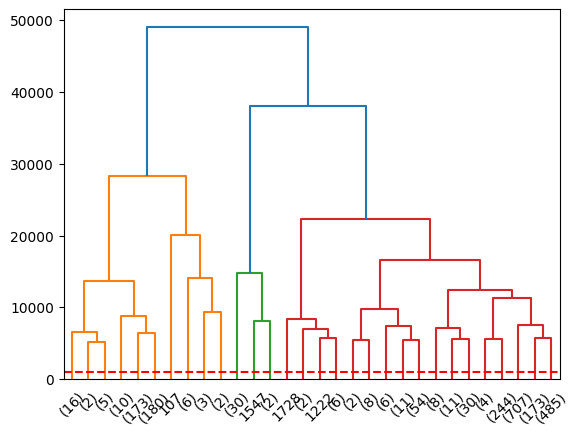

In [ ]:
from scipy.cluster.hierarchy import linkage as sp_linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt
xy = df[['easting','northing']].values
D = cdist(xy, xy, metric="cityblock")
Z = sp_linkage(squareform(D, checks=False), method="complete")
dendrogram(Z, truncate_mode="lastp", p=30)
plt.axhline(1000, color="r", ls="--")  # ton seuil
plt.show()

In [ ]:

cluster_col = 'cluster_diam_max'
cluster_comment2 = (
    "AgglomerativeClustering with Manhattan distance on utm coords, distance_threshold=1700 (meters), linkage='complete'"
)
fig=px.scatter_map(df, lat='Lat',lon='Lon',
                   color = df[cluster_col].astype(str),
                   hover_data={'easting','northing','borough' },
                   zoom = 10,
                   height=750,
                   title= cluster_comment2)
# fig_centers = px.scatter_map(
#     centres,
#     lat=centres['Lat'],  # northing
#     lon=centres['Lon'],  # easting
#     color='cluster',
#     hover_data = {'centre': 'centre',
#                   'Lat':'Lat','Lon':'Lon','n_points':'n_points','rayon_max':'rayon_max'},
#     #symbol='cluster',
#     #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
# )
# # Agrandir les croix
# fig_centers.update_traces(marker_size=20)
# # Ajouter toutes les traces des centroïdes
# for trace in fig_centers.data:
#     fig.add_trace(trace)

fig.show()

KeyError: 'cluster_diam_max'

## 2.4 Kcenter glouton

In [ ]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def kcenter_glouton(df, k=None, rayon=None, metric="cityblock",
                    cols=("easting", "northing"), D=None, premier=None):
    """k-center glouton (Gonzalez, farthest-first) : chaque point est à <= rayon de son centre.

    - k : nombre de centres voulu (optionnel)
    - rayon : rayon max (m) ; on ajoute des centres jusqu'à ce qu'il soit respecté (optionnel)
      -> au moins un des deux est requis ; si les deux sont donnés, on s'arrête au premier atteint
    - metric : 'cityblock' (Manhattan) ou 'euclidean', sur les colonnes `cols` (mètres)
    - D : matrice (n, n) de distances précalculées (ex. OSRM), remplace `metric`
    - premier : position (iloc) du 1er centre ; défaut : point le plus proche du barycentre
      (résultat déterministe)
    Retourne (labels : array (n,), centres : DataFrame cluster, idx_centre, n_points, rayon_max, cols...)
    """
    # --- Vérifications ---
    if k is None and rayon is None:
        raise ValueError("Donne k, rayon, ou les deux.")
    if k is not None and (int(k) != k or k < 1):
        raise ValueError("k doit être un entier >= 1.")
    if rayon is not None and rayon < 0:
        raise ValueError("rayon doit être >= 0.")
    if metric not in ("cityblock", "euclidean"):
        raise ValueError("metric doit être 'cityblock' ou 'euclidean'.")
    if any(c not in df.columns for c in cols):
        raise KeyError(f"Colonnes manquantes : {cols}")

    coords = df[list(cols)].to_numpy(dtype=float)
    n = len(coords)
    if n == 0:
        raise ValueError("DataFrame vide.")
    if not np.isfinite(coords).all():
        raise ValueError("NaN/inf dans les coordonnées.")
    if D is not None:
        D = np.asarray(D, dtype=float)
        if D.shape != (n, n):
            raise ValueError(f"D doit être de forme ({n}, {n}).")

    # Distances de tous les points vers le point i : O(n) mémoire, pas de matrice n x n
    def dist(i):
        return D[i] if D is not None else cdist(coords, coords[i:i + 1], metric=metric).ravel()

    if premier is None:
        premier = int(np.argmin(cdist(coords, coords.mean(axis=0, keepdims=True), metric=metric)))

    # --- Boucle gloutonne : le point le plus éloigné de tous les centres devient centre ---
    centres = [int(premier)]
    dmin = dist(premier)                    # distance de chaque point à son centre le plus proche
    labels = np.zeros(n, dtype=int)
    k_max = int(k) if k is not None else n

    while len(centres) < k_max:
        if rayon is not None and dmin.max() <= rayon:
            break
        j = int(np.argmax(dmin))
        if dmin[j] == 0:                    # tous les points restants sont des doublons de centres
            break
        d = dist(j)
        plus_proche = d < dmin              # points qui changent de centre
        labels[plus_proche] = len(centres)
        dmin = np.where(plus_proche, d, dmin)
        centres.append(j)

    # --- Tableau des centres (compatible avec le code de tracé précédent) ---
    stats = (pd.DataFrame({"cluster": labels, "d": dmin})
             .groupby("cluster")["d"].agg(n_points="size", rayon_max="max").reset_index())
    res = pd.DataFrame({"cluster": range(len(centres)), "idx_centre": centres}).merge(stats, on="cluster")
    for i, c in enumerate(cols):
        res[c] = coords[centres, i]
    for c in ("Lat", "Lon"):                # coordonnées géographiques si présentes dans df
        if c in df.columns:
            res[c] = df[c].to_numpy()[centres]
    return labels, res


# Utilisation
df["cluster_kc"], centres = kcenter_glouton(df, rayon=2000)

print("Nb clusters :", len(centres))
print("Rayon max observé :", round(centres["rayon_max"].max()), "m")

Nb clusters : 52
Rayon max observé : 1989 m


In [ ]:

cluster_col = 'cluster_kc'
cluster_comment2 = (
    "Clusters K center glouton with Manhattan distance on utm coords, distance_threshold=2000 (meters)"
)
fig=px.scatter_map(df, lat='Lat',lon='Lon',
                   color = df[cluster_col].astype(str),
                   hover_data={'easting','northing','borough' },
                   zoom = 10,
                   height=750,
                   title= cluster_comment2)

fig.show()

In [ ]:
# utm.from_latlon(latitude, longitude) extreme west @ glencove
# it's even same utm area 18T  
easting, northing, zone_number, zone_letter = utm.from_latlon(40.763 ,-73.5277)
print(easting, northing, zone_number, zone_letter)

624267.1949883323 4513490.96063987 18 T


In [ ]:
clusters_centers = matrix.reset_index().rename(columns={'index':"cluster"})
clusters_centers

,cluster,lat,lon
0,0,40.79,-73.94
1,1,40.71,-73.99
2,2,40.93,-73.66
3,3,40.75,-73.99
4,4,40.66,-73.78


## 2.5 Kmeans  

In [85]:
df_rawb.sample(5)

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough
180748,2014-07-19 22:47:00,40.7563,-73.9245,B02598,2014-07-19,19,22,5,7,2014,5_22,590784,4512261,18,T,Manhattan
499749,2014-09-18 10:45:00,40.7483,-73.9751,B02617,2014-09-18,18,10,3,9,2014,3_10,586523,4511322,18,T,Manhattan
5413,2014-06-05 18:45:00,40.7978,-73.9601,B02512,2014-06-05,5,18,3,6,2014,3_18,587725,4516832,18,T,Manhattan
143994,2014-05-13 22:24:00,40.7516,-73.9938,B02598,2014-05-13,13,22,1,5,2014,1_22,584941,4511670,18,T,Manhattan
288713,2014-06-04 06:08:00,40.7261,-73.9405,B02617,2014-06-04,4,6,2,6,2014,2_6,589474,4508892,18,T,Manhattan


In [86]:
df1fil_17.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2794 entries, 34594 to 564285
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date/Time    2794 non-null   datetime64[ns]
 1   Lat          2794 non-null   float64       
 2   Lon          2794 non-null   float64       
 3   Base         2794 non-null   object        
 4   date         2794 non-null   datetime64[ns]
 5   day          2794 non-null   int32         
 6   hour         2794 non-null   int32         
 7   weekday      2794 non-null   int32         
 8   month        2794 non-null   int32         
 9   year         2794 non-null   int32         
 10  schedule     2794 non-null   object        
 11  easting      2794 non-null   int64         
 12  northing     2794 non-null   int64         
 13  zone_number  2794 non-null   int64         
 14  zone_letter  2794 non-null   object        
 15  borough      2794 non-null   object        
dtypes: da

In [164]:
# kmeans 
# Import Standard Scaler
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = df1fil_17.copy()
title_data = df.attrs['title']
print(title_data)
# df[['easting', 'northing', 'zone_number', 'zone_letter']] = df.apply(
#     lambda row: utm.from_latlon(row['Lat'], row['Lon']), 
#     axis=1, 
#     result_type='expand'
# )
X0 = df[["Lat", "Lon"]]
X1 = df[['easting','northing']]
# Initialize StandardScaler
# StandardScaler will substract mean and divide by standard deviation to each observation
# sc = StandardScaler()

# Apply StandardScaler to X
# X = sc.fit_transform(X0)

# Visualize first five rows
# Standard scaler transform X as numpy array. Therefore you can't use .head()
X1[:5]

30 avril 2014 à 17h


,easting,northing
34594,586571,4512288
34595,584664,4510001
34596,585969,4511082
34597,586478,4512332
34598,584396,4512052


In [167]:
# Import K-Means

N_Kclusters = 15
# Instanciate KMeans with k=3 and initialisation with k-means++
# You should always use k-means++ as it alleviate the problem of local minimum convergence
kmeans = KMeans(n_clusters=N_Kclusters, random_state=0)

# Fit kmeans to our dataset
kmeans.fit(X1)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",15
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [101]:
cluster_centers = kmeans.cluster_centers_
cluster_centers

array([[ 586121.60106383, 4511896.19503546],
       [ 602735.54347826, 4500263.95652174],
       [ 584112.66348449, 4508472.96420048],
       [ 595780.63157895, 4513566.60526316],
       [ 570024.13333333, 4506125.4       ],
       [ 586376.58989899, 4513066.81212121],
       [ 584103.56491228, 4511163.61052632],
       [ 587187.36619718, 4516696.        ],
       [ 587728.37837838, 4503389.21621622],
       [ 588080.99509804, 4513835.03431373],
       [ 585305.08040201, 4510270.58542714],
       [ 587523.09090909, 4496954.81818182],
       [ 584202.10322581, 4506067.11612903],
       [ 588292.18      , 4508064.98      ],
       [ 593153.33333333, 4524342.5       ]])

In [168]:
# Cluster centers coordinates
# Let's use inverse transform to have the real coordinates
cluster_centers = kmeans.cluster_centers_
df['clusterKm'] = kmeans.labels_
df['clusterKm_int'] = df['clusterKm']
df['clusterKm'] = df['clusterKm'].astype(str)


# Let's get column names to facilita understanding
labels = ['Lat','Lon']
labels = ['easting','northing']
matrix = pd.DataFrame(cluster_centers, columns = labels).round(6)
matrix = pd.DataFrame(cluster_centers, columns = labels).round(0)

zone_number = df['zone_number'].values[0]
zone_letter = df['zone_letter'].values[0]
# zone_number = 18
# zone_letter = "T"

matrix[['Lat', 'Lon']] = matrix.apply(
        lambda row: utm.to_latlon(row["easting"], row["northing"],
                                  zone_number, zone_letter),
        axis=1,
        result_type='expand')  
        

# Create heatmap with plotly
import plotly.figure_factory as ff

fig = ff.create_annotated_heatmap(matrix.values,
                                  x = matrix.columns.tolist(),
                                  y = matrix.index.tolist())


fig.show()

In [169]:
kmeans.labels_

array([ 0, 10,  0, ...,  9,  6,  0], shape=(2794,), dtype=int32)

In [170]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2794 entries, 34594 to 564285
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date/Time      2794 non-null   datetime64[ns]
 1   Lat            2794 non-null   float64       
 2   Lon            2794 non-null   float64       
 3   Base           2794 non-null   object        
 4   date           2794 non-null   datetime64[ns]
 5   day            2794 non-null   int32         
 6   hour           2794 non-null   int32         
 7   weekday        2794 non-null   int32         
 8   month          2794 non-null   int32         
 9   year           2794 non-null   int32         
 10  schedule       2794 non-null   object        
 11  easting        2794 non-null   int64         
 12  northing       2794 non-null   int64         
 13  zone_number    2794 non-null   int64         
 14  zone_letter    2794 non-null   object        
 15  borough        2794 

In [171]:
cluster_centers

array([[ 586121.60106383, 4511896.19503546],
       [ 602735.54347826, 4500263.95652174],
       [ 584112.66348449, 4508472.96420048],
       [ 595780.63157895, 4513566.60526316],
       [ 570024.13333333, 4506125.4       ],
       [ 586376.58989899, 4513066.81212121],
       [ 584103.56491228, 4511163.61052632],
       [ 587187.36619718, 4516696.        ],
       [ 587728.37837838, 4503389.21621622],
       [ 588080.99509804, 4513835.03431373],
       [ 585305.08040201, 4510270.58542714],
       [ 587523.09090909, 4496954.81818182],
       [ 584202.10322581, 4506067.11612903],
       [ 588292.18      , 4508064.98      ],
       [ 593153.33333333, 4524342.5       ]])

In [172]:
clusters_centers = matrix.reset_index().rename(columns={'index':"cluster"})
clusters_centers = ajouter_borough(clusters_centers, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")

clusters_centers

df["cs_easting"]  = df["easting"]  - df["clusterKm_int"].astype(int).map(clusters_centers["easting"])
df["cs_northing"] = df["northing"] - df["clusterKm"].astype(int).map(clusters_centers["northing"])
df["dist_manhattan"] = df["cs_easting"].abs() + df["cs_northing"].abs()
dist_max = df.groupby("clusterKm").agg(
    dist=("dist_manhattan","max"),
    nb_points = ("dist_manhattan","size")).reset_index()
dist_max


,clusterKm,dist,nb_points
0,0,3020.0,565
1,1,8498.0,46
2,10,2642.0,398
3,11,7850.0,11
4,12,7316.0,155
5,13,4085.0,50
6,14,5249.0,6
7,2,6270.0,419
8,3,11706.0,38
9,4,6857.0,15


In [173]:
print(clusters_centers["cluster"].dtype, dist_max.reset_index().dtypes if dist_max.index.name == "clusterKm" else dist_max.dtypes)

int64 clusterKm     object
dist         float64
nb_points      int64
dtype: object


In [174]:

dist_max["clusterKm"] = dist_max["clusterKm"].astype(int)
 
clusters_centers2 = clusters_centers.merge(right=dist_max, how = "inner", left_on='cluster',right_on="clusterKm")
clusters_centers2 = clusters_centers2.drop(columns="clusterKm")
clusters_centers2["rad_km"] = (clusters_centers2["dist"]/1000).round(1)
clusters_centers2["cluster_rad"] = (
    clusters_centers2["cluster"].astype(str) + 
    " rad. " + clusters_centers2["rad_km"].astype(str) + " km"
)
clusters_centers2

,cluster,easting,northing,Lat,Lon,borough,dist,nb_points,rad_km,cluster_rad
0,0,586122.0,4511896.0,40.753515,-73.979775,Manhattan,3020.0,565,3.0,0 rad. 3.0 km
1,1,602736.0,4500264.0,40.646842,-73.784905,Queens,8498.0,46,8.5,1 rad. 8.5 km
2,2,584113.0,4508473.0,40.722891,-74.004031,Manhattan,6270.0,419,6.3,2 rad. 6.3 km
3,3,595781.0,4513567.0,40.767497,-73.865116,Queens,11706.0,38,11.7,3 rad. 11.7 km
4,4,570024.0,4506125.0,40.703059,-74.171101,Hors NYC,6857.0,15,6.9,4 rad. 6.9 km
5,5,586377.0,4513067.0,40.764035,-73.976593,Manhattan,2748.0,495,2.7,5 rad. 2.7 km
6,6,584104.0,4511164.0,40.747130,-74.003776,Manhattan,4260.0,284,4.3,6 rad. 4.3 km
7,7,587187.0,4516696.0,40.796637,-73.966491,Manhattan,23336.0,71,23.3,7 rad. 23.3 km
8,8,587728.0,4503389.0,40.676721,-73.961944,Brooklyn,6388.0,37,6.4,8 rad. 6.4 km
9,9,588081.0,4513835.0,40.770772,-73.956299,Manhattan,4934.0,204,4.9,9 rad. 4.9 km


In [175]:
clusters_centers2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   cluster      15 non-null     int64  
 1   easting      15 non-null     float64
 2   northing     15 non-null     float64
 3   Lat          15 non-null     float64
 4   Lon          15 non-null     float64
 5   borough      15 non-null     object 
 6   dist         15 non-null     float64
 7   nb_points    15 non-null     int64  
 8   rad_km       15 non-null     float64
 9   cluster_rad  15 non-null     object 
dtypes: float64(6), int64(2), object(2)
memory usage: 1.3+ KB


In [176]:
df_plot.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2794 entries, 34594 to 564285
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date/Time         2794 non-null   datetime64[ns]
 1   Lat               2794 non-null   float64       
 2   Lon               2794 non-null   float64       
 3   Base              2794 non-null   object        
 4   date              2794 non-null   datetime64[ns]
 5   day               2794 non-null   int32         
 6   hour              2794 non-null   int32         
 7   weekday           2794 non-null   int32         
 8   month             2794 non-null   int32         
 9   year              2794 non-null   int32         
 10  schedule          2794 non-null   object        
 11  easting           2794 non-null   int64         
 12  northing          2794 non-null   int64         
 13  zone_number       2794 non-null   int64         
 14  zone_letter       2794 

In [177]:
centres_plot

,cluster,easting,northing,Lat,Lon,borough,dist,nb_points,rad_km,cluster_rad,cluster_rad2
0,0,586122.0,4511896.0,40.753515,-73.979775,Manhattan,3020.0,565,3.0,0 rad. 3.0 km,0 rad. 3.0 km
1,1,602736.0,4500264.0,40.646842,-73.784905,Queens,8498.0,46,8.5,1 rad. 8.5 km,1 rad. 8.5 km
2,2,584113.0,4508473.0,40.722891,-74.004031,Manhattan,6270.0,419,6.3,2 rad. 6.3 km,2 rad. 6.3 km
3,3,595781.0,4513567.0,40.767497,-73.865116,Queens,11706.0,38,11.7,3 rad. 11.7 km,3 rad. 11.7 km
4,4,570024.0,4506125.0,40.703059,-74.171101,Hors NYC,6857.0,15,6.9,4 rad. 6.9 km,4 rad. 6.9 km
5,5,586377.0,4513067.0,40.764035,-73.976593,Manhattan,2748.0,495,2.7,5 rad. 2.7 km,5 rad. 2.7 km
6,6,584104.0,4511164.0,40.747130,-74.003776,Manhattan,4260.0,284,4.3,6 rad. 4.3 km,6 rad. 4.3 km
7,7,587187.0,4516696.0,40.796637,-73.966491,Manhattan,23336.0,71,23.3,7 rad. 23.3 km,7 rad. 23.3 km
8,8,587728.0,4503389.0,40.676721,-73.961944,Brooklyn,6388.0,37,6.4,8 rad. 6.4 km,8 rad. 6.4 km
9,9,588081.0,4513835.0,40.770772,-73.956299,Manhattan,4934.0,204,4.9,9 rad. 4.9 km,9 rad. 4.9 km


In [180]:
# want to plot points w/ different colors
# associated to cluster groups :
import plotly.graph_objects as go

print(f"nb clusters: {kmeans.n_clusters}")
print(f"labels: {kmeans.labels_}")
print(f"type X0: {type(X0)}")

title = f"NYC pickups {title_data} - Kmeans avec {N_Kclusters} clusters"

X0.head()

#palette = px.colors.qualitative.Plotly  # ou D3, Set1, Dark24 si > 10 clusters
palette = px.colors.qualitative.Alphabet #+ px.colors.qualitative.Dark24 
#labels = sorted(df["clusterKm"].astype(str).unique(), key=int)
#cmap = {l: palette[i % len(palette)] for i, l in enumerate(labels)}
# Ordre alphabétique unique, réutilisé partout
#ordre = sorted(df_plot["clusterId_radius"].unique())
ordre = (
    centres_plot[["cluster", "cluster_rad"]]
    .drop_duplicates("cluster_rad")      # un seul libellé par valeur
    .sort_values("cluster")["cluster_rad"]
    .astype(str)
    .tolist()
)
cmap = {k: palette[i % len(palette)] for i, k in enumerate(ordre)} # même ordre que la légende (clés str requises)


df_plot = df.assign(cluster_str=df["clusterKm"].astype(str))
df_plot["clusterId_radius"] =  df_plot["clusterKm_int"].map(clusters_centers2["cluster_rad"])
#centres_plot = centres.assign(cluster_str=centres["cluster"].astype(str))
centres_plot = clusters_centers2.assign(cluster_rad2=clusters_centers2["cluster_rad"].astype(str))
#centres_plot["cluster_rad"] = centres_plot["cluster_str"] + centres_plot["dist"]

fig1 = px.scatter_map(
    df_plot,
    lat='Lat',lon='Lon',
    color='clusterId_radius',
    color_discrete_map = cmap,
    category_orders={"clusterId_radius": ordre},
    height = 650,
    #showlegend=False,
    hover_data = {'clusterKm':True},
    zoom=11,
    #map_style='open-street-map'
    title = title)

fig_halo = px.scatter_map(
    centres_plot,
    lat='Lat',  # northing
    lon='Lon',  # easting
    category_orders={"cluster_rad2": ordre},
    #hover_data = {'cluster','Lat','Lon',"borough",'nb_points','dist'},
    #symbol='cluster',
    #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
)

fig_centers = px.scatter_map(
    centres_plot,
    lat='Lat',  # northing
    lon='Lon',  # easting
    color='cluster_rad2',
    color_discrete_map = cmap,
    hover_data = {'cluster':True},
    category_orders={"cluster_rad2": ordre},
    #hover_data = {'cluster','Lat','Lon',"borough",'nb_points','dist'},
    #symbol='cluster',
    #symbol_map={0: 'cross', 1: 'cross', 2: 'cross',3: 'cross', 4: 'cross'}
)
note = "rayons max des clusters calculés en distances de Manhattan"
fig_halo.update_traces(marker={"size":18,"color":"black"}, showlegend=False)
fig1.add_traces(fig_halo.data)

fig_centers.update_traces(marker_size=15, showlegend=False)
# Ajouter toutes les traces des centroïdes

fig1.add_traces(fig_centers.data)

fig1.show()

nb clusters: 15
labels: [ 0 10  0 ...  9  6  0]
type X0: <class 'pandas.core.frame.DataFrame'>


Comments about Kmeans : 
- Euclidian distance and not Citiblock (manhattan) distance
- not same order of magnitude clusters radius 
- 

### 2.5.2 elbow method

In [184]:
# select K optimal clusters with elbow method :
#
# Let's create a loop that will collect the Within-sum-of-square (wcss) for each value K
# Let's use .inertia_ parameter to get the within sum of square value for each value K
wcss =  []
k = []
for i in range (1,30):
    kmeans = KMeans(n_clusters= i, random_state = 0, n_init = 'auto')
    kmeans.fit(X1)
    wcss.append(kmeans.inertia_)
    k.append(i)
    print("WCSS for K={} --> {}".format(i, wcss[-1])) 

WCSS for K=1 --> 53569881224.90515
WCSS for K=2 --> 34198241430.870438
WCSS for K=3 --> 19991810339.488155
WCSS for K=4 --> 16155089984.671778
WCSS for K=5 --> 13193757852.65927
WCSS for K=6 --> 10097166018.378323
WCSS for K=7 --> 8301337034.038799
WCSS for K=8 --> 6593876523.386015
WCSS for K=9 --> 6225894680.837776
WCSS for K=10 --> 5489914608.837523
WCSS for K=11 --> 4782776041.168012
WCSS for K=12 --> 4452253438.412537
WCSS for K=13 --> 4035566380.072841
WCSS for K=14 --> 3574215694.194229
WCSS for K=15 --> 3445837050.1511536
WCSS for K=16 --> 3321424083.892711
WCSS for K=17 --> 3148248241.9154005
WCSS for K=18 --> 2876185229.736673
WCSS for K=19 --> 2727864783.8513765
WCSS for K=20 --> 2378859761.0620685
WCSS for K=21 --> 2105156136.983906
WCSS for K=22 --> 1995729816.9653034
WCSS for K=23 --> 1902399409.289584
WCSS for K=24 --> 1848880289.3283458
WCSS for K=25 --> 1781088363.3416257
WCSS for K=26 --> 1645167676.6098669
WCSS for K=27 --> 1549881533.9809275
WCSS for K=28 --> 148580

In [185]:
# Create DataFrame
wcss_frame = pd.DataFrame(wcss)
k_frame = pd.Series(k)

# Create figure
fig= px.line(
    wcss_frame,
    x=k_frame,
    y=wcss_frame.iloc[:,-1]
)

# Create title and axis labels
fig.update_layout(
    yaxis_title="Inertia",
    xaxis_title="# Clusters",
    title="Inertia per cluster"
)

# Render
#fig.show(renderer="notebook")
fig.show() # if using workspace

Optimal number of clusters is more close to 8 than 15

In [ ]:

def stats_distance_clusters(X, kmeans):
    """Distance de Manhattan point→centre : max, moyenne, nb de points par cluster."""
    X = np.asarray(X, dtype=float)
    if X.shape[1] != kmeans.cluster_centers_.shape[1]:
        raise ValueError("X n'a pas le même nombre de colonnes que celles utilisées pour entraîner kmeans.")

    labels = kmeans.predict(X)
    d = np.abs(X - kmeans.cluster_centers_[labels]).sum(axis=1)

    return (
        pd.DataFrame({"cluster": labels, "dist": d})
        .groupby("cluster")["dist"]
        .agg(dist_max="max", dist_moy="mean", n_points="size")
    )

print(stats_distance_clusters(X1, kmeans))

             dist_max     dist_moy  n_points
cluster                                     
0         3020.593972   755.540768       565
1         8497.586957   823.758979        46
2         6269.699284  1001.806939       419
3        11706.763158  2865.034626        38
4         6857.266667  2371.733333        15
5         2747.777778   857.291966       495
6         4259.954386   976.678008       284
7        23336.366197  2383.052966        71
8         6387.837838  2290.280497        37
9         4934.039216  1158.438437       204
10        2641.505025   807.687558       398
11        7850.090909  3938.991736        11
12        7316.219355  1540.924454       155
13        4084.800000  1405.368800        50
14        5249.833333  2828.388889         6


c:\work\Venv\venv_311_jedha\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning:

X does not have valid feature names, but KMeans was fitted with feature names



In [198]:
# let's define use a norm for displacement in streets ;
# 5 to 7 minutes of wait ; 
AVERAGE_WAIT = 5 # min 
MAX_WAIT= 7 # min 
# average speed NY : 6 to 7 km/h / other sources speak of 15 km/h 
AVERAGE_SPEED= 15 # km/h 
max_distance = MAX_WAIT/60 * AVERAGE_SPEED
# distance manhattan
max_distance  # in kilometers

#average duration of taxi service : 11 min and 4.5 km distance, so average speed is 24.5 km/h



1.75

# 4. Build a robust target with NYC speed survey 

## 4.1 recherche de la vitesse moyenne par borough et par heure
a partir des donnnées des taxis jaunes (page TLC Trip Record Data du site nyc.gov)
pour etre sur d'etre entre 5 et 7 minutes, au lieu de prendre la mediane de la vitesse
il faut plutot prendre la vitesse la plus lente au 80e percentile et viser 5 minutes !

In [199]:
from pathlib import Path
from urllib.request import urlopen, Request
import shutil

import pandas as pd
import pyarrow.parquet as pq

URL_TLC = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_{annee}-{mois:02d}.parquet"

# Noms de colonnes possibles selon l'année -> nom normalisé
ALIAS = {
    "tpep_pickup_datetime": "pickup_datetime", "pickup_datetime": "pickup_datetime",
    "tpep_dropoff_datetime": "dropoff_datetime", "dropoff_datetime": "dropoff_datetime",
    "trip_distance": "trip_distance",
    "pickup_longitude": "pickup_lon", "pickup_latitude": "pickup_lat",
    "dropoff_longitude": "dropoff_lon", "dropoff_latitude": "dropoff_lat",
    "PULocationID": "PULocationID", "DOLocationID": "DOLocationID",
    "passenger_count": "passenger_count",
}


def telecharger_tlc(annee: int, mois: int, dossier: str | Path = "data_tlc", force: bool = False) -> Path:
    """Télécharge un fichier mensuel (cache local). Retourne le chemin."""
    dossier = Path(dossier)
    dossier.mkdir(parents=True, exist_ok=True)
    chemin = dossier / f"yellow_tripdata_{annee}-{mois:02d}.parquet"
    if chemin.exists() and chemin.stat().st_size > 0 and not force:
        return chemin

    tmp = chemin.with_suffix(".tmp")  # écriture atomique : pas de fichier corrompu si coupure
    try:
        req = Request(URL_TLC.format(annee=annee, mois=mois), headers={"User-Agent": "Mozilla/5.0"})
        with urlopen(req, timeout=60) as r, open(tmp, "wb") as f:
            shutil.copyfileobj(r, f)
        tmp.replace(chemin)
    except Exception as e:
        tmp.unlink(missing_ok=True)
        raise RuntimeError(f"Téléchargement impossible ({annee}-{mois:02d}) : {e}") from e
    return chemin


def charger_tlc_jaune(
    annee: int,
    mois: int | list[int],
    dossier: str | Path = "data_tlc",
    nettoyer: bool = True,
    echantillon: float | None = None,
    seed: int = 42,
    ) -> pd.DataFrame:
    """Charge les taxis jaunes TLC pour une année et un ou plusieurs mois.

    Colonnes normalisées : pickup_datetime, dropoff_datetime, trip_distance (miles),
    + pickup_lon/lat (anciens fichiers) ou PULocationID/DOLocationID (récents),
    + duree_h et vitesse_kmh si nettoyer=True.
    echantillon : fraction (0-1] conservée par mois, pour limiter la mémoire.
    """
    mois_liste = [mois] if isinstance(mois, int) else list(mois)
    morceaux = []

    for m in mois_liste:
        chemin = telecharger_tlc(annee, m, dossier)
        # Colonnes réellement présentes dans ce fichier
        presentes = pq.read_schema(chemin).names
        a_lire = [c for c in presentes if c in ALIAS]
        df = pd.read_parquet(chemin, columns=a_lire).rename(columns=ALIAS)
        df = df.loc[:, ~df.columns.duplicated()]  # sécurité si deux alias pointent vers le même nom

        for c in ("pickup_datetime", "dropoff_datetime"):
            df[c] = pd.to_datetime(df[c], errors="coerce")

        if echantillon is not None:
            if not 0 < echantillon <= 1:
                raise ValueError("echantillon doit être dans ]0, 1]")
            df = df.sample(frac=echantillon, random_state=seed)

        # Les fichiers contiennent parfois des courses hors du mois demandé
        debut = pd.Timestamp(annee, m, 1)
        df = df[(df["pickup_datetime"] >= debut) & (df["pickup_datetime"] < debut + pd.offsets.MonthBegin(1))]
        morceaux.append(df)

    out = pd.concat(morceaux, ignore_index=True)

    if nettoyer:
        out["duree_h"] = (out["dropoff_datetime"] - out["pickup_datetime"]).dt.total_seconds() / 3600
        out["vitesse_kmh"] = out["trip_distance"] * 1.609344 / out["duree_h"]
        masque = (out["duree_h"] > 1 / 60) & (out["trip_distance"] > 0) & out["vitesse_kmh"].between(2, 100)
        if {"pickup_lon", "pickup_lat"} <= set(out.columns):  # bbox approximative de NYC
            masque &= out["pickup_lon"].between(-74.3, -73.6) & out["pickup_lat"].between(40.45, 41.0)
        out = out[masque].reset_index(drop=True)

    return out

In [ ]:
import pandas as pd

def vitesse_par_borough_heure(trips: pd.DataFrame) -> pd.DataFrame:
    """Vitesse mediane (km/h) par borough de départ et heure. Colonnes attendues :
    pickup_datetime, dropoff_datetime, trip_distance (miles), borough."""
    t = trips.copy()
    duree_h = (t["dropoff_datetime"] - t["pickup_datetime"]).dt.total_seconds() / 3600
    t["vitesse_kmh"] = t["trip_distance"] * 1.609344 / duree_h
    # Filtrage des valeurs aberrantes (durée nulle, GPS erroné)
    t = t[(duree_h > 1 / 60) & t["vitesse_kmh"].between(2, 100)]
    t["hour"] = t["pickup_datetime"].dt.hour
    return t.groupby(["borough", "hour"])["vitesse_kmh"].median().unstack("borough")

# p20 : p20 = df["vitesse"].quantile(0.20)
def vitesse_p20_par_borough_heure(trips: pd.DataFrame, quantile = 0.2) -> pd.DataFrame:
    """Vitesse moyenne (km/h) par borough de départ et heure. Colonnes attendues :
    pickup_datetime, dropoff_datetime, trip_distance (miles), borough."""
    t = trips.copy()
    duree_h = (t["dropoff_datetime"] - t["pickup_datetime"]).dt.total_seconds() / 3600
    t["vitesse_kmh"] = t["trip_distance"] * 1.609344 / duree_h
    # Filtrage des valeurs aberrantes (durée nulle, GPS erroné)
    t = t[(duree_h > 1 / 60) & t["vitesse_kmh"].between(2, 100)]
    t["hour"] = t["pickup_datetime"].dt.hour
    df = t.groupby(["borough", "hour"])["vitesse_kmh"].quantile(quantile).unstack("borough")
    df.attrs["quantile"] = quantile
    df.attrs["title"] = f"vitesse km/h au {quantile*100:E2.0} percentile"
    return 


In [201]:
trips = charger_tlc_jaune(2014, [4, 5, 6], echantillon=0.2)   # 20 % des courses, par mois
print(trips.columns.tolist(), len(trips))

['pickup_datetime', 'dropoff_datetime', 'passenger_count', 'trip_distance', 'PULocationID', 'DOLocationID', 'duree_h', 'vitesse_kmh'] 8533896


In [202]:
zones = pd.read_csv("uber-trip-data/taxi-zone-lookup.csv")[["LocationID", "Borough"]]
trips = trips.merge(zones, left_on="PULocationID", right_on="LocationID", how="left").rename(columns={"Borough": "borough"})

In [203]:
trips.head()

,pickup_datetime,dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,duree_h,vitesse_kmh,LocationID,borough
0,2014-04-02 12:26:28,2014-04-02 12:42:22,1,0.7,162,161,0.265000,4.251097,162,Manhattan
1,2014-04-19 11:43:30,2014-04-19 12:02:31,1,3.8,144,142,0.316944,19.295202,144,Manhattan
2,2014-04-30 15:27:55,2014-04-30 16:04:14,1,6.1,68,40,0.605278,16.218997,68,Manhattan
3,2014-04-25 10:30:11,2014-04-25 10:40:05,1,0.8,125,211,0.165000,7.802880,125,Manhattan
4,2014-04-11 08:51:22,2014-04-11 09:01:01,1,1.5,238,142,0.160833,15.009426,238,Manhattan


In [219]:

vitesse_borough = trips.assign(hour=trips["pickup_datetime"].dt.hour).assign(weekday=trips["pickup_datetime"].dt.weekday).groupby(["borough", "weekday", "hour"])["vitesse_kmh"].median().unstack("borough")
vitesse_borough_p20 = trips.assign(hour=trips["pickup_datetime"].dt.hour).assign(weekday=trips["pickup_datetime"].dt.weekday).groupby(["borough", "weekday", "hour"])["vitesse_kmh"].quantile(0.2).unstack("borough")


In [205]:
pd.set_option('display.max_rows', None)
display(vitesse_borough.sample(5))

borough           Bronx   Brooklyn        EWR  Manhattan     Queens  \
weekday hour                                                          
2       1     32.830618  25.371709        NaN  26.947155  47.162553   
4       22    23.312497  20.373764        NaN  18.346522  41.038272   
6       2     26.554176  23.685757        NaN  24.025752  25.860625   
        3     28.324454  24.998477  27.036979  25.312012  25.389768   
4       8     16.093440  18.967634  46.996643  14.605811  25.523182   

borough       Staten Island    Unknown  
weekday hour                            
2       1               NaN  26.397873  
4       22        28.374093  18.248820  
6       2               NaN  23.596274  
        3         67.214602  24.681419  
4       8               NaN  14.831941

In [221]:
vitesse_borough.head(5)

borough           Bronx   Brooklyn  EWR  Manhattan     Queens  Staten Island  \
weekday hour                                                                   
0       0     29.040794  25.160167  NaN  25.962059  52.594948            NaN   
        1     27.671521  25.918687  NaN  27.680717  47.488839            NaN   
        2     26.164819  26.355040  NaN  28.968192  31.979329            NaN   
        3     26.715110  26.496682  NaN  29.687355  30.492834            NaN   
        4     25.974812  29.710966  NaN  33.077144  30.593470            NaN   

borough         Unknown  
weekday hour             
0       0     26.163959  
        1     27.072204  
        2     28.165509  
        3     29.967095  
        4     32.864268

In [220]:
vitesse_borough_p20.head(5)

borough           Bronx   Brooklyn  EWR  Manhattan     Queens  Staten Island  \
weekday hour                                                                   
0       0     20.142784  20.116800  NaN  19.527189  32.331228            NaN   
        1     22.283225  20.585266  NaN  20.611983  24.062911            NaN   
        2     19.969521  21.000145  NaN  21.196238  21.243341            NaN   
        3     21.887396  20.419827  NaN  21.919243  21.881156            NaN   
        4     21.484742  22.825021  NaN  23.931980  22.312541            NaN   

borough         Unknown  
weekday hour             
0       0     19.939220  
        1     20.064165  
        2     21.680975  
        3     20.803453  
        4     22.533769

In [206]:
# fill Nan values : 
import numpy as np
import pandas as pd


def imputer_par_ratio(
    mat: pd.DataFrame,
    refs: list[str] | None = None,
    min_points: int = 5,
) -> pd.DataFrame:
    """Remplit les NaN d'une matrice (weekday, hour) x borough.

    NaN(borough b, créneau t) = référence(t) * ratio(b),
    avec ratio(b) = médiane de b / référence sur les créneaux où les deux existent.
    Repli : interpolation sur l'heure au sein de chaque jour, puis ffill/bfill.
    """
    out = mat.copy()
    if refs is None:
        # Boroughs bien renseignés par défaut (à adapter)
        refs = [c for c in ("Bronx", "Brooklyn", "Manhattan") if c in out.columns]
    if not refs:
        raise ValueError("Aucune colonne de référence trouvée dans la matrice")

    for col in out.columns:
        if not out[col].isna().any():
            continue

        # Référence du créneau = médiane des autres boroughs de référence
        autres = [c for c in refs if c != col]
        if not autres:
            continue
        ref = out[autres].median(axis=1)

        # Ratio estimé sur les créneaux où col et ref sont tous deux connus
        ok = out[col].notna() & ref.notna()
        if ok.sum() < min_points:
            print(f"[{col}] {ok.sum()} créneaux communs < {min_points} : imputation par ratio ignorée")
            continue
        ratio = (out.loc[ok, col] / ref[ok]).median()

        manquant = out[col].isna() & ref.notna()
        out.loc[manquant, col] = ref[manquant] * ratio

    # Repli pour les NaN restants : interpolation sur l'heure, jour par jour
    out = out.groupby(level="weekday", group_keys=False).apply(
        lambda g: g.interpolate(limit_direction="both")
    )
    return out


vitesse_borough_ok = imputer_par_ratio(vitesse_borough)
print(vitesse_borough_ok.isna().sum())  # colonnes encore vides = pas assez de données

borough
Bronx            0
Brooklyn         0
EWR              0
Manhattan        0
Queens           0
Staten Island    0
Unknown          0
dtype: int64


In [222]:
vitesse_borough_p20_ok = imputer_par_ratio(vitesse_borough_p20)

In [225]:
vitesse_borough_ok.head(5)

borough           Bronx   Brooklyn        EWR  Manhattan     Queens  \
weekday hour                                                          
0       0     29.040794  25.160167  33.324434  25.962059  52.594948   
        1     27.671521  25.918687  35.518668  27.680717  47.488839   
        2     26.164819  26.355040  33.828857  28.968192  31.979329   
        3     26.715110  26.496682  34.291037  29.687355  30.492834   
        4     25.974812  29.710966  38.136464  33.077144  30.593470   

borough       Staten Island    Unknown  
weekday hour                            
0       0         36.265934  26.163959  
        1         38.653850  27.072204  
        2         36.814882  28.165509  
        3         37.317858  29.967095  
        4         41.502715  32.864268

In [224]:
vitesse_borough_p20_ok.head(7)

borough           Bronx   Brooklyn        EWR  Manhattan     Queens  \
weekday hour                                                          
0       0     20.142784  20.116800  30.351507  19.527189  32.331228   
        1     22.283225  20.585266  31.098621  20.611983  24.062911   
        2     19.969521  21.000145  31.684266  21.196238  21.243341   
        3     21.887396  20.419827  33.022918  21.919243  21.881156   
        4     21.484742  22.825021  34.437574  23.931980  22.312541   
        5     23.596139  24.138972  41.521075  23.174554  28.205871   
        6     18.083174  22.139485  28.659784  18.995536  24.683112   

borough       Staten Island    Unknown  
weekday hour                            
0       0         35.300074  19.939220  
        1         36.168999  20.064165  
        2         36.850128  21.680975  
        3         38.407037  20.803453  
        4         40.052340  22.533769  
        5         68.279416  22.852685  
        6         33.332529  19.059343

In [208]:
# plotting of speeds per borough & weekday : 
# jours :
JOURS = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]


In [227]:
def tracer_vitesses(mat: pd.DataFrame, 
                    colonnes_par_ligne: int = 4, 
                    hauteur: int = 650,title=None):
    """Tracé en subplots des vitesses medianes
    Une fenêtre par weekday, une courbe (couleur) par borough.
    mat : index (weekday, hour), colonnes = boroughs."""
    if title==None:
        title = "NYC yellow trip data avril-juin 2014 : Vitesse médiane par heure, jour de semaine et borough"
    else:
        title = "NYC yellow trip data avril-juin 2014 : " + title
    if list(mat.index.names) != ["weekday", "hour"]:
        raise ValueError(f"Index attendu (weekday, hour), reçu : {mat.index.names}")

    # Format long : une ligne par (weekday, hour, borough)
    long = (
        mat.dropna(axis=1, how="all")           # retire les boroughs sans aucune donnée
           .rename_axis(columns="borough")
           .stack()
           .rename("vitesse_kmh")
           .reset_index()
    )
    long["jour"] = long["weekday"].map(dict(enumerate(JOURS)))

    fig = px.line(
        long,
        x="hour", y="vitesse_kmh",
        color="borough",
        facet_col="jour",
        facet_col_wrap=colonnes_par_ligne,       # 7 jours -> 2 lignes (4 + 3)
        category_orders={"jour": JOURS},
        markers=True,
        height=hauteur,
        title=title,
        labels={"hour": "Heure", "vitesse_kmh": "Vitesse (km/h)", "borough": "Borough"},
    )
    fig.update_xaxes(dtick=3)
    fig.update_yaxes(matches="y")                # même échelle partout pour comparer les jours
    fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))  # titre = "Lun", "Mar"...
    return fig


In [228]:


tracer_vitesses(vitesse_borough_ok,hauteur=900).show()

In [229]:
tracer_vitesses(vitesse_borough_p20_ok, title ="Vitesse 20e percentile par heure, jour de semaine et borough" )

# 5. Final Clustering strategie : 
On va rechercher des clusters de diametre max par borough :  
    D = V_mediane_borough * T_attente_max  avec une distance de Manhattan
  
Dans une démarche d'optimisation on pourrait encore rafiner:  
- en utilisant une vitesse mediane par zones des Borough, 
    sachant que certaines statistiques parlent de zones de Manhattan ou la vitesse moyenne peut descendre à 7 km/h  
    dans les heures de très forte affluence. 
- en utilisant la vraie distance issue des cartographies (googlemap par exemple)  
    mais qui nécessite de grosses puissances de calcul

Pour contrôler le diametre maximal d'un cluster, les méthodes classiques comme K-means et DBSCAN sont en échec :  
- Kmeans minimise la variance et ne borne rien et ne peut utiliser que la distance euclidienne , pas la distance de manhattan... 
- DBSCAN enchaine les points voisins et peut produre des clusters allongés sans limite de diamètre
  
Plusieurs méthodes, d'apres la litterature, pourraient convenir: 
  
| Méthode | Garantie | Volume |
|---|---|---|
| **Glouton à rayon variable** | Diamètre ≤ 2·r du centre (leader) | Gros volumes |
| **CAH lien complet, distances normalisées** | Toute paire (i, j) du cluster :<br>d(i,j) ≤ (D_i + D_j) / 2 | Environ 8k points max |
| **CAH lien complet par zone**<br>(une CAH par borough, seuil propre) | Exacte dans chaque zone | Moyen |
| **Quadtree adaptatif**<br>(on coupe tant que la diagonale > D(zone)) | Borne par la taille de cellule | Excellent |
  
  
Nous allons utiliser Aglomerative clustering couplée au seuil D ou 


In [288]:
import time
import warnings
from functools import lru_cache

import h3
import numpy as np
import pandas as pd
from pyproj import Transformer
import plotly.express as px
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial import ConvexHull, cKDTree
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans

CLES = ["weekday", "hour", "borough"]
JOURS = ["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"]
PALETTE = px.colors.qualitative.Dark24
CMAP = {f"c{i}": c for i, c in enumerate(PALETTE)} | {"halo": "black"}
ROT_DEG = 29        # rotation des axes E/N avant la transformation L1 (grille des rues de manhattan)
_T = Transformer.from_crs("EPSG:32618", "EPSG:4326", always_xy=True)   # UTM 18N (NYC) -> lon/lat


# def _xy(g: pd.DataFrame) -> np.ndarray:
#     """Coordonnées UTM (mètres) d'un créneau."""
#     return g[["easting", "northing"]].to_numpy(dtype=float)

def ajouter_uv(d, rot_deg=None):
    """x,y = E/N tournés ; u = x+y, v = x-y (la distance L1 devient max(|du|,|dv|))."""
    a = np.radians(ROT_DEG if rot_deg is None else rot_deg)
    c, s = np.cos(a), np.sin(a)
    E, N = d["easting"].to_numpy(float), d["northing"].to_numpy(float)
    x, y = E * c - N * s, E * s + N * c
    d["u"], d["v"] = x + y, x - y
    return d


def _uv(g):
    return g[["u", "v"]].to_numpy(dtype=float)


def _linf(X, pt):
    """Distance L∞ (= L1 d'origine) de chaque ligne de X au point pt."""
    return np.abs(X - pt).max(axis=1)


# ============================================================
# 1. MÉTHODES : f(g, D) -> labels (entiers 0..k-1), garantie : rayon L1 <= D (carré de côté 2D en u,v)
# ============================================================

def m_glouton(g, D):
    """Leaders par densité décroissante, boule L1 de rayon D autour du leader."""
    X, n = _uv(g), len(g)
    voisins = cKDTree(X).query_ball_point(X, r=D, p=np.inf)
    densite = np.fromiter((len(v) for v in voisins), dtype=int, count=n)
    labels, k = np.full(n, -1, dtype=int), 0
    for i in np.argsort(-densite, kind="stable"):
        if labels[i] != -1:
            continue
        idx = np.asarray(voisins[i], dtype=int)
        idx = idx[labels[idx] == -1]
        labels[idx] = k
        k += 1
    return labels


def m_cah(g, D, n_max=5000):
    """Lien complet en L∞ coupé à 2D : étendues u et v <= 2D, donc rayon <= D (exact)."""
    n = len(g)
    if n > n_max:
        print(f"CAH : {n} points > {n_max}, repli sur le glouton pour ce créneau")
        return m_glouton(g, D)
    Z = linkage(_uv(g), method="complete", metric="chebyshev")
    return fcluster(Z, t=2 * D, criterion="distance") - 1


def m_kcenter(g, D):
    """Farthest-first : on ajoute un centre tant qu'un point est à plus de D de tous les centres."""
    X, n = _uv(g), len(g)
    labels = np.zeros(n, dtype=int)
    dist = _linf(X, X[0])
    k = 1
    while dist.max() > D and k < n:
        j = int(dist.argmax())
        dj = _linf(X, X[j])
        plus_proche = dj < dist
        dist = np.where(plus_proche, dj, dist)
        labels[plus_proche] = k
        k += 1
    return labels


def m_kmeans_bisect(g, D, seed=42):
    """On coupe en 2 (K-means) tout cluster dont l'étendue u ou v dépasse 2D."""
    X, n = _uv(g), len(g)
    labels, k = np.zeros(n, dtype=int), 0
    pile = [np.arange(n)]
    while pile:
        idx = pile.pop()
        P = X[idx]
        if len(idx) == 1 or np.ptp(P, axis=0).max() <= 2 * D:
            labels[idx], k = k, k + 1
            continue
        moitie = KMeans(n_clusters=2, n_init=3, random_state=seed).fit(P).labels_
        a, b = idx[moitie == 0], idx[moitie == 1]
        if len(a) == 0 or len(b) == 0:            # points confondus : coupure impossible
            labels[idx], k = k, k + 1
            continue
        pile += [a, b]
    return labels


def m_quadtree(g, D, profondeur_max=30):
    """Quadtree en (u,v) : on coupe tant que le côté d'une cellule dépasse 2D."""
    X, n = _uv(g), len(g)
    labels, k = np.zeros(n, dtype=int), 0
    x0, y0 = X.min(axis=0)
    x1, y1 = X.max(axis=0)
    pile = [(np.arange(n), x0, y0, x1 + 1e-6, y1 + 1e-6, 0)]
    while pile:
        idx, ax, ay, bx, by, prof = pile.pop()
        if len(idx) == 1 or max(bx - ax, by - ay) <= 2 * D or prof >= profondeur_max:
            labels[idx], k = k, k + 1
            continue
        mx, my = (ax + bx) / 2, (ay + by) / 2
        droite, haut = X[idx, 0] >= mx, X[idx, 1] >= my
        for dr, ha, cell in ((False, False, (ax, ay, mx, my)), (True, False, (mx, ay, bx, my)),
                             (False, True, (ax, my, mx, by)), (True, True, (mx, my, bx, by))):
            sub = idx[(droite == dr) & (haut == ha)]
            if len(sub):
                pile.append((sub, *cell, prof + 1))
    return labels


@lru_cache(maxsize=8)
def table_h3(rot_deg=0.0, res_min=5, res_max=11, lat_ref=40.75, lon_ref=-73.98):
    """Rayon L1 minimax (m) d'une cellule H3 de référence à NYC, pour chaque résolution."""
    a = np.radians(rot_deg)
    c, s = np.cos(a), np.sin(a)

    def rayon(cell):
        p = np.array(h3.cell_to_boundary(cell))                      # (lat, lon)
        x = (p[:, 1] - lon_ref) * 111_320 * np.cos(np.radians(lat_ref))
        y = (p[:, 0] - lat_ref) * 110_540
        xr, yr = x * c - y * s, x * s + y * c
        return float(max(np.ptp(xr + yr), np.ptp(xr - yr)) / 2)     # demi-étendue max en (u,v)

    return pd.Series({r: rayon(h3.latlng_to_cell(lat_ref, lon_ref, r)) for r in range(res_min, res_max + 1)})


def m_h3(g, D, marge=1.05):
    """Résolution H3 la plus grossière dont le rayon L1 de cellule * marge <= D (discret, approximatif)."""
    t = table_h3(float(ROT_DEG))
    ok = t[t * marge <= D]
    res = int(ok.index.min()) if len(ok) else int(t.index.max())
    cells = [h3.latlng_to_cell(la, lo, res) for la, lo in zip(g["Lat"], g["Lon"])]
    return pd.factorize(pd.Series(cells))[0]


METHODES = {"glouton": m_glouton, "cah": m_cah, "kcenter": m_kcenter,
            "kmeans_bisect": m_kmeans_bisect, "quadtree": m_quadtree, "h3": m_h3}


# ============================================================
# 2. PIPELINE : application par créneau + centres + évaluation
# ============================================================

def clusteriser(df, D, methode="glouton", centre="minimax", **kw):
    """D : Series (weekday, hour, borough) = rayon max L1 en mètres.
    centre : 'minimax' (centre du carré englobant, garantit rayon <= D) ou 'point' (pickup réel le plus proche)."""
    f = METHODES[methode] if isinstance(methode, str) else methode
    requis = {*CLES, "easting", "northing", "Lat", "Lon"}
    if not requis <= set(df.columns):
        raise KeyError(f"Colonnes manquantes : {sorted(requis - set(df.columns))}")
    if centre not in ("minimax", "point"):
        raise ValueError("centre doit valoir 'minimax' ou 'point'")

    d = ajouter_uv(df.reset_index(drop=True).copy())
    d["R_m"] = D.reindex(pd.MultiIndex.from_frame(d[CLES])).to_numpy()
    if d["R_m"].isna().any():
        print(f"{d['R_m'].isna().sum()} points sans rayon cible -> médiane utilisée")
        d["R_m"] = d["R_m"].fillna(D.median())

    cluster, decalage = np.full(len(d), -1, dtype=int), 0
    for _, pos in d.groupby(CLES).indices.items():
        g = d.iloc[pos]
        lab = np.zeros(len(g), dtype=int) if len(g) == 1 else np.asarray(f(g, float(g["R_m"].iloc[0]), **kw))
        cluster[pos] = lab + decalage
        decalage += int(lab.max()) + 1
    d["cluster"] = cluster
    d = d[d["cluster"] >= 0]
    return d, calculer_centres(d, centre)


def calculer_centres(d, centre="minimax"):
    c = d.groupby("cluster").agg(
        weekday=("weekday", "first"), hour=("hour", "first"), borough=("borough", "first"),
        R_m=("R_m", "first"), n_points=("u", "size"),
        umin=("u", "min"), umax=("u", "max"), vmin=("v", "min"), vmax=("v", "max"),
    )
    c["cu"], c["cv"] = (c["umin"] + c["umax"]) / 2, (c["vmin"] + c["vmax"]) / 2   # centre minimax
    c = c.drop(columns=["umin", "umax", "vmin", "vmax"])

    if centre == "point":     # pickup réel le plus proche du centre minimax (distance L1)
        dist = np.maximum((d["u"] - d["cluster"].map(c["cu"])).abs(), (d["v"] - d["cluster"].map(c["cv"])).abs())
        idx = dist.groupby(d["cluster"]).idxmin().to_numpy()
        for nom, col in (("lat", "Lat"), ("lon", "Lon"), ("E", "easting"), ("N", "northing"), ("cu", "u"), ("cv", "v")):
            c[nom] = d.loc[idx, col].to_numpy()
    else:                      # retour de (u,v) vers E/N puis lat/lon
        a = np.radians(ROT_DEG)
        co, si = np.cos(a), np.sin(a)
        x, y = (c["cu"] + c["cv"]) / 2, (c["cu"] - c["cv"]) / 2
        c["E"], c["N"] = x * co + y * si, -x * si + y * co
        lon, lat = _T.transform(c["E"].to_numpy(), c["N"].to_numpy())
        c["lat"], c["lon"] = lat, lon
    return c.reset_index()


def evaluer(d, centres):
    """Rayon L1 réel (max des distances au centre) et conformité à D, par cluster."""
    ci = centres.set_index("cluster")
    r = np.maximum((d["u"] - d["cluster"].map(ci["cu"])).abs(), (d["v"] - d["cluster"].map(ci["cv"])).abs())
    c = centres.copy()
    c["rayon_m"] = c["cluster"].map(r.groupby(d["cluster"]).max())
    c["conforme"] = c["rayon_m"] <= c["R_m"] * (1 + 1e-9)
    return c


def comparer(df, D, methodes=None, centre="minimax", **kw):
    methodes = methodes or list(METHODES)
    lignes, resultats = [], {}
    for m in methodes:
        t0 = time.perf_counter()
        d, c = clusteriser(df, D, m, centre=centre, **kw)
        c = evaluer(d, c)
        resultats[m] = (d, c)
        lignes.append({"methode": m, "n_clusters": len(c), "points/cluster": c["n_points"].mean(),
                       "part_conformes": c["conforme"].mean(), "remplissage_moy": (c["rayon_m"] / c["R_m"]).mean(),
                       "singletons": (c["n_points"] == 1).mean(), "temps_s": time.perf_counter() - t0})
    return pd.DataFrame(lignes).set_index("methode").round(3), resultats

# ============================================================
# 3. VISUALISATION : scatter_map animé (1 frame = weekday + heure)
# ============================================================


def preparer_animation(d, centres, min_points=5, weekdays=None, heures=None, max_points=60_000, seed=42):
    """Retourne (points, centres, ordre_frames). Couleur et frame fixés au niveau du cluster."""
    c = centres[centres["n_points"] >= min_points].copy()
    if weekdays is not None:
        c = c[c["weekday"].isin(weekdays)]
    if heures is not None:
        c = c[c["hour"].isin(list(heures))]
    if c.empty:
        raise ValueError("Aucun cluster après filtrage : baisse min_points ou élargis les filtres")

    c["frame"] = (c["weekday"].map(dict(enumerate(JOURS))) + " " + c["hour"].astype(int).astype(str).str.zfill(2) + "h")
    c = c.sort_values(["weekday", "hour", "cluster"])
    # Couleur = rang du cluster dans son frame (une seule source de vérité)
    c["couleur"] = (c.groupby("frame").cumcount() % len(PALETTE)).map(lambda i: PALETTE[i])
    ordre = c["frame"].drop_duplicates().tolist()

    # Les points héritent frame et couleur de LEUR cluster
    p = d[d["cluster"].isin(c["cluster"])].copy()
    ref = c.set_index("cluster")
    p["frame"] = p["cluster"].map(ref["frame"])
    p["couleur"] = p["cluster"].map(ref["couleur"])
    if max_points is not None and len(p) > max_points:
        p = p.sample(max_points, random_state=seed)
    return p, c, ordre


def animer(d, centres, titre="Clusters et points d'attente", zoom=10.5, hauteur=750,
           duree_ms=700, taille_point=7, taille_centre=14, **kw):
    p, c, ordre = preparer_animation(d, centres, **kw)
    pg, cg = dict(tuple(p.groupby("frame"))), dict(tuple(c.groupby("frame")))
    p_vide, c_vide = p.iloc[:0], c.iloc[:0]

    def traces(f):
        """3 traces dans un ordre fixe : points -> halo noir -> centres (dessinés au-dessus)."""
        pf, cf = pg.get(f, p_vide), cg.get(f, c_vide)
        txt_c = [f"{b}<br>{int(n)} pickups" + (f"<br>D = {dm:.0f} m" if pd.notna(dm) else "")
                 for b, n, dm in zip(cf["borough"], cf["n_points"], cf.get("R_m", pd.Series(np.nan, index=cf.index)))]
        base = dict(mode="markers", showlegend=False)
        return [
            go.Scattermap(lat=pf["Lat"], lon=pf["Lon"], marker=dict(size=taille_point, color=list(pf["couleur"])),
                          text=pf["borough"], hoverinfo="text", **base),
            go.Scattermap(lat=cf["lat"], lon=cf["lon"], marker=dict(size=taille_centre + 4, color="black"),
                          hoverinfo="skip", **base),
            go.Scattermap(lat=cf["lat"], lon=cf["lon"], marker=dict(size=taille_centre, color=list(cf["couleur"])),
                          text=txt_c, hoverinfo="text", **base),
        ]

    param = lambda dur: dict(frame=dict(duration=dur, redraw=True), transition=dict(duration=0))
    fig = go.Figure(
        data=traces(ordre[0]),
        frames=[go.Frame(name=f, data=traces(f), traces=[0, 1, 2]) for f in ordre],
    )
    fig.update_layout(
        title=titre, height=hauteur, margin=dict(l=0, r=0, t=40, b=0), showlegend=False,
        map=dict(style="open-street-map", zoom=zoom, center=dict(lat=float(c["lat"].mean()), lon=float(c["lon"].mean()))),
        updatemenus=[dict(
            type="buttons", showactive=False, x=0.02, y=0.02, xanchor="left", yanchor="bottom",
            buttons=[
                dict(label="▶ Lecture", method="animate", args=[None, dict(**param(duree_ms), fromcurrent=True)]),
                dict(label="⏸ Pause", method="animate", args=[[None], dict(mode="immediate", **param(0))]),
            ],
        )],
        sliders=[dict(
            active=0, x=0.15, len=0.83, currentvalue=dict(prefix="Créneau : "), ticklen=0,
            steps=[dict(method="animate", label=f, args=[[f], dict(mode="immediate", **param(0))]) for f in ordre],
        )],
    )
    return fig

In [289]:
#import plotly.graph_objects as go   # à ajouter aux imports


def animer_legende(d, centres, titre="Clusters : rayon L1 max", zoom=10.5, hauteur=750,
                   duree_ms=700, taille_point=7, taille_centre=14, max_legende=24, **kw):
    """Comme animer(), mais la légende affiche « Cluster n · r km » pour chaque frame.
    r = distance de Manhattan max entre le centroïde et le point le plus loin (km).
    max_legende : nb max d'entrées de légende par frame (les autres centres restent affichés, sans légende)."""
    if not {"u", "v", "cluster"} <= set(d.columns):
        raise KeyError("d doit contenir u, v et cluster (sortie de clusteriser)")

    centres = evaluer(d, centres)                          # ajoute 'rayon_m' (calculé sur TOUS les points)
    p, c, ordre = preparer_animation(d, centres, **kw)
    pg, cg = dict(tuple(p.groupby("frame"))), dict(tuple(c.groupby("frame")))
    p_vide, c_vide = p.iloc[:0], c.iloc[:0]
    n_slots = min(int(c.groupby("frame").size().max()), max_legende)   # nb de traces "légende" fixe

    def txt(r):
        return f"{r['borough']}<br>{int(r['n_points'])} pickups<br>rayon L1 max = {r['rayon_m'] / 1000:.2f} km"

    def traces(f):
        """Ordre fixe : points, halo, n_slots centres avec légende, reste des centres sans légende."""
        pf, cf = pg.get(f, p_vide), cg.get(f, c_vide).reset_index(drop=True)
        base = dict(mode="markers")
        out = [
            go.Scattermap(lat=pf["Lat"], lon=pf["Lon"], marker=dict(size=taille_point, color=list(pf["couleur"])),
                          text=pf["borough"], hoverinfo="text", showlegend=False, **base),
            go.Scattermap(lat=cf["lat"], lon=cf["lon"], marker=dict(size=taille_centre + 4, color="black"),
                          hoverinfo="skip", showlegend=False, **base),
        ]
        for k in range(n_slots):
            if k < len(cf):
                r = cf.iloc[k]
                out.append(go.Scattermap(
                    lat=[r["lat"]], lon=[r["lon"]], marker=dict(size=taille_centre, color=r["couleur"]),
                    name=f"Cluster {int(r['cluster'])} · {r['rayon_m'] / 1000:.2f} km",
                    text=[txt(r)], hoverinfo="text", showlegend=True, **base))
            else:   # slot inutilisé dans ce frame : trace vide, masquée dans la légende
                out.append(go.Scattermap(lat=[], lon=[], marker=dict(size=taille_centre), name="",
                                         showlegend=False, **base))
        reste = cf.iloc[n_slots:]
        out.append(go.Scattermap(lat=reste["lat"], lon=reste["lon"],
                                 marker=dict(size=taille_centre, color=list(reste["couleur"])),
                                 text=[txt(r) for _, r in reste.iterrows()], hoverinfo="text",
                                 showlegend=False, **base))
        return out

    idx_traces = list(range(n_slots + 3))
    param = lambda dur: dict(frame=dict(duration=dur, redraw=True), transition=dict(duration=0))
    fig = go.Figure(data=traces(ordre[0]),
                    frames=[go.Frame(name=f, data=traces(f), traces=idx_traces) for f in ordre])
    fig.update_layout(
        title=titre, height=hauteur, margin=dict(l=0, r=0, t=40, b=0), showlegend=True,
        legend=dict(title="Cluster · rayon L1 max", x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.85)"),
        map=dict(style="open-street-map", zoom=zoom,
                 center=dict(lat=float(c["lat"].mean()), lon=float(c["lon"].mean()))),
        updatemenus=[dict(
            type="buttons", showactive=False, x=0.02, y=0.02, xanchor="left", yanchor="bottom",
            buttons=[
                dict(label="▶ Lecture", method="animate", args=[None, dict(**param(duree_ms), fromcurrent=True)]),
                dict(label="⏸ Pause", method="animate", args=[[None], dict(mode="immediate", **param(0))]),
            ],
        )],
        sliders=[dict(
            active=0, x=0.15, len=0.83, currentvalue=dict(prefix="Créneau : "), ticklen=0,
            steps=[dict(method="animate", label=f, args=[[f], dict(mode="immediate", **param(0))]) for f in ordre],
        )],
    )
    return fig



In [290]:
debut
fin

Timestamp('2014-09-21 23:59:59')

In [291]:
df_rawb.head(2)

,Date/Time,Lat,Lon,Base,date,day,hour,weekday,month,year,schedule,easting,northing,zone_number,zone_letter,borough
0,2014-04-01 00:11:00,40.7690,-73.9549,B02512,2014-04-01,1,0,1,4,2014,1_0,588201,4513640,18,T,Manhattan
1,2014-04-01 00:17:00,40.7267,-74.0345,B02512,2014-04-01,1,0,1,4,2014,1_0,581535,4508867,18,T,Hors NYC


In [292]:
# preparation des donnees 
# choix : 2 premieres semaines de septembre, avec du fort trafic
# df : donnees des pickups
debut, fin = pd.Timestamp("2014-09-08"), pd.Timestamp("2014-09-21 23:59:59")
df = df_rawb[df_rawb["Date/Time"].between(debut, fin)]

# R : donnees des rayons par borough : 
# R : Series indexée par (weekday, hour, borough)
T_attente_max = 7/60 # minutes/60
#V=D/T : D = V*T 
R_p20 = vitesse_borough_p20_ok * T_attente_max * 1000 # D est en metres
R_m = vitesse_borough_ok * T_attente_max * 1000 # D est en metres
# 
R_p20["Hors NYC"] = R_p20["EWR"]

R_p20 = (
        R_p20.rename_axis(columns="borough")
           .stack()                                  # colonnes -> niveau d'index 'borough'
           .rename("R_m")
           .sort_index()
    )
R_p20 = R_p20[~R_p20.index.duplicated(keep="first")]         # sécurité si doublons

R_m["Hors NYC"] = R_m["EWR"]
R_m = (
        R_m.rename_axis(columns="borough")
           .stack()                                  # colonnes -> niveau d'index 'borough'
           .rename("R_m")
           .sort_index()
    )
R_m = R_m[~R_m.index.duplicated(keep="first")] 


In [293]:
R_m.info()

<class 'pandas.core.series.Series'>
MultiIndex: 1344 entries, (np.int32(0), np.int32(0), 'Bronx') to (np.int32(6), np.int32(23), 'Unknown')
Series name: R_m
Non-Null Count  Dtype  
--------------  -----  
1344 non-null   float64
dtypes: float64(1)
memory usage: 15.4+ KB


In [294]:
R.sample(5)

weekday  hour  borough      
6        20    EWR              2887.253194
1        23    Hors NYC         3281.698359
4        14    Queens           2460.707855
0        2     Hors NYC         3696.497699
         13    Staten Island    2129.162112
Name: D_m, dtype: float64

In [295]:
#R[(R["hour"] == 12) & (R["weekday"] == 3)]
def printR_jeu_12(R):
    R = R[(R.index.get_level_values("hour") == 12) & (R.index.get_level_values("weekday") == 3)]
    
    res2 = R.xs((3, 12), level=("weekday", "hour"))
    res2 = np.ceil(res2/10)*10
    return res2.round(0).astype(int)
    
res_m = printR_jeu_12(R_m)
res_p20 = printR_jeu_12(R_p20)
   
print(res_m)
res_p20    
# res_p20 = R_p20[(R.index.get_level_values("hour") == 12) & (R.index.get_level_values("weekday") == 3)]
# R_m
# res2 = R.xs((3, 12), level=("weekday", "hour"))
# res2 = np.ceil(res2/10)*10
# res2.round(0).astype(int)

borough
Bronx            2070
Brooklyn         2190
EWR              6500
Hors NYC         6500
Manhattan        1390
Queens           3330
Staten Island    2890
Unknown          1470
Name: R_m, dtype: int64


borough
Bronx            1690
Brooklyn         1560
EWR              6500
Hors NYC         6500
Manhattan         950
Queens           2500
Staten Island    2730
Unknown           960
Name: R_m, dtype: int64

In [ ]:
# D : Series indexée par (weekday, hour, borough), diamètre max en mètres
# (par ex. D = d_max_depuis_vitesse(mat_ok, minutes=3), vu plus haut)

# 1) Comparer toutes les méthodes sur les mêmes données et la même cible
R = R_p20  # target is radius from speedtrafic 20e percentile 
resume, res = comparer(df, R)            # ou comparer(df, D, ["glouton", "cah", "h3"])
print(resume)
resume_rot, _ = comparer(df, R)
print(resume_rot)

# 2) Visualiser une méthode
d, centres = res["glouton"]
animer(d, centres, titre="Glouton", weekdays=[0, 4], heures=range(6, 22)).show()


CAH : 5044 points > 5000, repli sur le glouton pour ce créneau
CAH : 5045 points > 5000, repli sur le glouton pour ce créneau
               n_clusters  points/cluster  part_conformes  remplissage_moy  \
methode                                                                      
glouton             19407          25.624             1.0            0.383   
cah                 14900          33.375             1.0            0.533   
kcenter             19795          25.122             1.0            0.367   
kmeans_bisect       15962          31.154             1.0            0.526   
quadtree            26135          19.028             1.0            0.282   
h3                  37210          13.364             1.0            0.194   

               singletons  temps_s  
methode                             
glouton             0.352   19.476  
cah                 0.206   25.568  
kcenter             0.302    1.857  
kmeans_bisect       0.213  369.448  
quadtree            0.356  

In [ ]:

# 3) Points d'attente exportables
#centres[["weekday", "hour", "borough", "lat", "lon", "n_points"]].to_csv("points_attente.csv", index=False)

In [309]:

# Usage
#d2, centres2 = clusteriser(df, R, "glouton")
fig = animer_legende(d, centres, titre="Glouton max radius L1",min_points=5, weekdays=[4,5,6], heures=range(4, 23))
fig.show()

In [298]:
def verifier_centres(d, centres):
    """Chaque point doit être à moins de D de son centre ; affiche les clusters fautifs."""
    m = d.merge(centres[["cluster", "E", "N"]], on="cluster", suffixes=("", "_c"))
    m["dist_centre_m"] = np.hypot(m["easting"] - m["E"], m["northing"] - m["N"])
    r = m.groupby("cluster").agg(dmax=("dist_centre_m", "max"), R_m=("R_m", "first"))
    fautifs = r[r["dmax"] > r["R_m"]]
    print(f"{len(fautifs)} clusters sur {len(r)} avec un point plus loin que R de son centre")
    return fautifs

verifier_centres(d, centres)
animer(d, centres, weekdays=[0, 4], heures=range(6, 22)).show()

0 clusters sur 19407 avec un point plus loin que R de son centre


In [299]:
import geopandas as gpd
import pandas as pd

def localiser_points(df, zones_path, nj_path=None, lat="Lat", lon="Lon", col_nj=None):
    """Ajoute LocationID, Borough et Zone à df. Hors zones TLC : municipalité NJ, sinon 'Hors NYC'."""
    pts = gpd.GeoDataFrame(df.copy(), geometry=gpd.points_from_xy(df[lon], df[lat]), crs="EPSG:4326")

    zones = gpd.read_file(zones_path).to_crs("EPSG:4326")
    print(zones.columns.tolist())                         # vérifier les noms de champs
    zones = zones.rename(columns={"borough": "Borough", "zone": "Zone"})[["LocationID", "Borough", "Zone", "geometry"]]
    res = gpd.sjoin(pts, zones, how="left", predicate="within").drop(columns="index_right")
    res = res[~res.index.duplicated(keep="first")]        # un point sur une frontière peut matcher 2 zones

    if nj_path is not None:
        nj = gpd.read_file(nj_path).to_crs("EPSG:4326")
        print(nj.columns.tolist())
        if col_nj is None:
            raise ValueError(f"Précise col_nj (nom de municipalité) parmi : {nj.columns.tolist()}")
        sans = res["Borough"].isna()
        if sans.any():
            j = gpd.sjoin(res.loc[sans, ["geometry"]], nj[[col_nj, "geometry"]], how="left", predicate="within")
            j = j[~j.index.duplicated(keep="first")]
            res.loc[sans, "Borough"] = j[col_nj].fillna("Hors NYC").to_numpy()

    res["Borough"] = res["Borough"].fillna("Hors NYC")
    return pd.DataFrame(res.drop(columns="geometry"))

# Exemple
# df = localiser_points(df, "taxi_zones_wgs84/taxi_zones.shp", "nj_municipalites.geojson", col_nj="<champ_nom>")

In [300]:
# Position moyenne par label : Manhattan doit être vers lat 40.78, Brooklyn vers 40.65
print(df.groupby("borough")[["Lat", "Lon"]].agg(["mean", "min", "max"]).round(3))

taxi_zones_wgs84 = "nyu_2451_36743_WGS84/nyu_2451_36743.shp"
# Comparaison avec le borough calculé par les taxi zones (fonction localiser_points)
ref = localiser_points(df, taxi_zones_wgs84)
print(pd.crosstab(df["borough"], ref["Borough"].reindex(df.index)))   # la diagonale doit dominer

                  Lat                     Lon                
                 mean     min     max    mean     min     max
borough                                                      
Bronx          40.854  40.800  40.913 -73.894 -73.932 -73.783
Brooklyn       40.689  40.572  40.739 -73.965 -74.041 -73.859
Hors NYC       40.755  40.193  41.348 -74.020 -74.774 -72.716
Manhattan      40.748  40.694  40.877 -73.986 -74.018 -73.908
Queens         40.723  40.560  40.799 -73.853 -73.960 -73.701
Staten Island  40.609  40.535  40.648 -74.106 -74.193 -74.060
['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']
Borough        Bronx  Brooklyn   EWR  Hors NYC  Manhattan  Queens  \
borough                                                             
Bronx           3859         0     0         0          0       0   
Brooklyn           0     68572     0         0          0       1   
Hors NYC           0         0  3244      9437          0       0   
Manhattan  

In [301]:
df = ajouter_borough(df, path_nyc_borough, lat="Lat", lon="Lon",
                      hors_zone="Hors NYC")


In [302]:
# Comparaison avec le borough calculé par les taxi zones (fonction localiser_points)
ref = localiser_points(df, "nyu_2451_36743_WGS84/nyu_2451_36743.shp")
print(pd.crosstab(df["borough"], ref["Borough"].reindex(df.index)))   

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']
Borough        Bronx  Brooklyn   EWR  Hors NYC  Manhattan  Queens  \
borough                                                             
Bronx           3859         0     0         0          0       0   
Brooklyn           0     68572     0         0          0       1   
Hors NYC           0         0  3244      9437          0       0   
Manhattan          0         1     0       120     374199       0   
Queens             0         0     0         2          0   37705   
Staten Island      0         0     0         0          0       0   

Borough        Staten Island  
borough                       
Bronx                      0  
Brooklyn                   0  
Hors NYC                   0  
Manhattan                  0  
Queens                     0  
Staten Island            144  


In [303]:
loc = localiser_points(df, taxi_zones_wgs84)     # + nj_path si besoin
df["borough"] = loc["Borough"].to_numpy()                          # même ordre que df

#D = preparer_D(mat_D, unite="km", df=df)
resume, res = comparer(df, R)

['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']
CAH : 5044 points > 5000, repli sur le glouton pour ce créneau
CAH : 5043 points > 5000, repli sur le glouton pour ce créneau


In [304]:
d, centres = res["glouton"]
verifier_centres(d, centres)
animer(d, centres, titre="Glouton", weekdays=[0,3,4], heures=range(6, 22)).show()

0 clusters sur 19519 avec un point plus loin que R de son centre


In [310]:
d2, centres2 = res["kmeans_bisect"]
animer_legende(d2, centres2, titre="kmeans_bisect", weekdays=[4,5,6], heures=range(6, 22)).show()

In [ ]:
# pour demain : 

# ajouter les hoverdata :
# - les hover data des points montrant la zone taxi, l'heure de pickup et le numero du cluster,
# - ceux des centres montrant la zone taxi et le numero du cluster et le rayon calculé du cluster  

# fabriquer un streamlit avec la visu par modele et par frame (!) 
  